# ESA data: Factor Analysis (PCA + varimax) and Feature Selection on the LST cell table

**What does this notebook do?** It takes the combined cell table (`master_lst_cell.csv`, 1,671 cells × 21 columns) and applies the two exercise sheets (*Factor Analysis 18.09* and *Feature Selection 22.09*) on top of the decisions that our Step 1 EDA pointed to.

**How it builds on the EDA** (source: *Step 1 – EDA*, section *Implications for modelling*; NB §n = step in the EDA notebook):

| EDA finding | What we do about it here |
|---|---|
| Only 1,161 cells have LST (NB §1, impl. 1) | Our working set is those 1,161 cells. LST is the *target* and never enters the factor analysis. |
| Missing values in five predictors, cause not confirmed (NB §1, impl. 2) | **Part 2** investigates the gaps, and a `MISSING_STRATEGY` switch sets how we treat them. **Part 6** compares the strategies. |
| NDVI–fvc r=0.96 and imperviousness–built-up r=0.97 are near-duplicates (NB §6, impl. 3) | The factor analysis groups them; feature selection prunes duplicates via correlation clusters and *group-wise* importance. |
| Neighbouring cells resemble each other, so a random split leaks (NB §7, impl. 4) | Spatial split (easternmost 20% = test) and spatial cross-validation in longitude blocks. Everything is fitted on train only. |
| The relationship is not equally tight along the whole range (NB §6, impl. 5) | Besides linear methods (PCA, Lasso) we also use a random forest, plus a simple baseline (imperviousness only). |

**An analogy that carries the whole notebook.** Think of the 13 variables as 13 questions in a questionnaire and each cell as a respondent. *Factor analysis* asks: which few underlying "attitudes" explain the answers? *Feature selection* asks: which of the questions do we actually need to predict the respondent's answer on the outcome (LST)? The first *creates new axes* from the old ones; the second *chooses among the old ones*.

**Language and sources.** Each section points to the part of the exercise sheet it corresponds to. Numbers quoted from the EDA come from the EDA note; all numbers for *this* table are computed in the code cells.

**How to read the results.** The notebook shows *associations on one cell grid on one morning* (13 June 2023), not causes (EDA: *What the EDA cannot tell us*).

### Course sources we align with
Every choice below is tied to the course material. We cite it in the text with these short forms:

| Short form | Source |
|---|---|
| **Karam (2026a)** | Karam, A. (2026). *Factor analysis* [lecture slides, 18-09-2026]. MSc Digital Innovation & Management, Managing Business Analytics & Data-driven Decision-Making. |
| **Karam (2026b)** | Karam, A. (2026). *Dimension reduction (PCA)* [lecture slides on feature selection / dimension reduction, 22-09-2026]. Same course. |
| **Field et al. (2012)** | Field, A., Miles, J., & Field, Z. (2012). *Discovering statistics using R*, ch. 17 "Exploratory factor analysis". Sage. |
| **Géron (ch. 8)** | Géron, A. *Hands-On Machine Learning with Scikit-Learn and TensorFlow*, ch. 8 "Dimensionality reduction". O'Reilly. |
| **Park et al. (2022)** | Park, E. H., Werder, K., Cao, L., & Ramesh, B. (2022). Why do family members reject AI in health care? Competing effects of emotions. *Journal of Management Information Systems, 39*(3), 765–792. |

**What the sources change in this version** (all decisions are listed in Part 8): we (1) say explicitly that our "factor analysis" is a PCA on physical indicators, not a model of reflective latent constructs; (2) report communalities and check the conditions under which Kaiser's rule is valid (Karam 2026a; Field et al. 2012, §17.3.5, §17.3.8); (3) check the determinant and correlations above .8 (Field et al. 2012, §17.4.2); (4) use a loading cut-off of 0.4 (Field et al. 2012, §17.3.9.2); (5) add parallel analysis and an oblique (oblimin) rotation next to scree/Kaiser and varimax (Field et al. 2012, §17.3.8–17.3.9); (6) treat the number of PCA components as a hyperparameter tuned by spatial cross-validation and report the information lost (Géron, ch. 8); (7) always compare against the **original features first** (Karam 2026b; Géron, ch. 8).

## Part 0. Setup

The packages are the same as in the sheets. If `factor_analyzer` or `kneed` is missing, remove the `#` in the cell below and run it once.

In [1]:
# pip install factor-analyzer kneed

In [2]:
import json
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.feature_selection import RFE, RFECV, mutual_info_regression
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from factor_analyzer.factor_analyzer import Rotator, calculate_bartlett_sphericity, calculate_kmo
from kneed import KneeLocator

warnings.filterwarnings("ignore")

# Plot style: calm, thin lines, consistent colours (blue = train / primary, orange = test / secondary)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#3987e5", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_bluered", ["#256abf", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

### Configuration: where we change our choices

Everything we might want to change is in this one cell. The most important choices:

* `MISSING_STRATEGY`: how we treat missing values (**still awaiting our professor's answer**, see Part 2). We currently fill building height with 0 where there are no buildings and drop the few rows with other gaps.
* `FEATURES`: candidate variables. Columns we deliberately leave out are listed in `EXCLUDED` with reasons.
* `TEST_FRACTION`: share of the 1,161 LST cells that we hold out completely (easternmost cells).

In [3]:
DATA_PATH = "master_lst_cell.csv"      # the CSV must be in the same folder as the notebook
OUTPUT_DIR = "outputs_fa_fs"          # tables for the group's models are saved here

ID, LON, LAT = "lst_cell_id", "lst_cell_lon", "lst_cell_lat"
TARGET = "lst_downscaled_C"           # LST in °C (the EDA kept °C and dropped the Kelvin columns)

FEATURES = [
    "ndvi_mean", "fvc_mean", "imd_2024_pct_mean", "tcd_2023_pct_mean",
    "elevation_m_mean", "slope_deg_mean",
    "share_wc_tree", "share_wc_grass", "share_wc_built", "share_wc_water",
    "share_ua_street_tree", "share_building", "bbh_mean_where_built_m",
]

EXCLUDED = {
    "lst_downscaled_K": "LST in Kelvin = target + 273.15 (a pure rewrite of the target)",
    "lst_interpolated_K": "also an LST version (only present where the target is present): would leak the target",
    "imd_2021_pct_mean": "near-duplicate of imd_2024 (checked in Part 2); the EDA used 2024",
    "n_pixels_10m": "describes how many 10 m pixels the cell covers (data quality), not the surface",
    "lst_cell_lon / lst_cell_lat": "used only for the spatial split, not as predictors",
    "lst_cell_id": "identifier",
}

BBH = "bbh_mean_where_built_m"        # building height (empty = no buildings according to the column description)

# --- Choices awaiting the professor ---------------------------------------------------------
MISSING_STRATEGY = "structural_zero"  # our current choice: building height empty = no buildings -> 0; drop only rows with other NaN (change to test the others)
STRATEGIES = {
    "structural_zero": "Building height: empty -> 0 (no buildings; tested in Part 2). Other rows with NaN are dropped.",
    "complete_case":   "Drop all rows with NaN in any feature (including building height).",
    "drop_bbh":        "Drop the building-height column; drop other rows with NaN.",
    "median_all":      "Median imputation (fitted on train) of all NaN, including building height.",
    "iterative":       "Building height: empty -> 0; other NaN imputed with IterativeImputer (fitted on train).",
}

# --- Method choices -----------------------------------------------------------------------
TEST_FRACTION = 0.20      # easternmost 20% of the LST cells = test (as in the group's random forest)
N_FOLDS = 5               # spatial cross-validation folds (longitude blocks)
RANDOM_STATE = 42
MSA_MIN = 0.5             # variables with MSA below this threshold are left out of the factor analysis
N_COMPONENTS = None       # None = use Kaiser (eigenvalue > 1); otherwise an integer
LOADING_CUTOFF = 0.4      # |loading| that counts as "belongs to the factor" (Stevens via Field et al. 2012, §17.3.9.2: interpret |loading| > 0.4; the slides use 0.3)
PARALLEL_REPS = 500       # random reorderings used for parallel analysis (Field et al. 2012, §17.3.8)
OBLIQUE_METHOD = "oblimin"  # oblique rotation to compare with varimax (Field et al. 2012, §17.3.9.1)
TWIN_R = 0.90             # |Spearman| above this = "duplicates" (same cluster)
VAR_MIN = 0.005           # minimum variance (after 0-1 scaling) in the filter step
FILTER_MIN_RHO = 0.20     # minimum |Spearman| with LST to pass the filter step
MIN_PERM_DELTA = 0.01     # minimum increase in MAE (°C) under permutation to count as important
MIN_VOTES = 3             # number of methods (of 5) that must select a feature
EVALUATE_ON_TEST = True   # show results on the test set once at the end (Part 5.6)

os.makedirs(OUTPUT_DIR, exist_ok=True)
assert MISSING_STRATEGY in STRATEGIES

## Part 1. Load the data and check it against the EDA

**Why first?** If the table does not match the EDA numbers, everything below rests on sand. The cell checks the numbers the EDA note reports (NB §1 and §6) and compares the Pearson correlations with LST to the EDA table *How each variable relates to LST*.

The FS sheet asks "what do we do with categorical columns?" (dummy encoding). Here **all 21 columns are numeric**, so the sheet's `do_dummy_encoding` is not needed.

In [4]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Duplicate ids:", df[ID].duplicated().sum())

EDA = {"rows": 1671, "columns": 21, "LST missing": 510, "building height missing": 324,
       "fvc missing": 67, "imperviousness missing": 42, "NDVI missing": 6, "tree cover missing": 1}
NOW = {"rows": len(df), "columns": df.shape[1], "LST missing": int(df[TARGET].isna().sum()),
       "building height missing": int(df[BBH].isna().sum()), "fvc missing": int(df["fvc_mean"].isna().sum()),
       "imperviousness missing": int(df["imd_2024_pct_mean"].isna().sum()),
       "NDVI missing": int(df["ndvi_mean"].isna().sum()), "tree cover missing": int(df["tcd_2023_pct_mean"].isna().sum())}
check = pd.DataFrame({"EDA note": EDA, "this table": NOW})
check["match"] = np.where(check["EDA note"] == check["this table"], "ok", "DIFFERS")
display(check)

lst_df = df[df[TARGET].notna()].copy().reset_index(drop=True)
print(f"\nWorking set (cells with LST): {len(lst_df)} of {len(df)}")

EDA_R = {"share_wc_built": 0.84, "imd_2024_pct_mean": 0.83, "share_building": 0.77, "fvc_mean": -0.77,
         "ndvi_mean": -0.73, "tcd_2023_pct_mean": -0.60, "slope_deg_mean": 0.11, "elevation_m_mean": 0.08}
mine = {c: lst_df[[c, TARGET]].corr().iloc[0, 1] for c in EDA_R}
rcheck = pd.DataFrame({"Pearson r (EDA)": EDA_R, "Pearson r (here)": mine}).round(2)
rcheck["difference"] = (rcheck["Pearson r (here)"] - rcheck["Pearson r (EDA)"]).round(2)
display(rcheck)

Shape: (1671, 21)
Duplicate ids: 0


,EDA note,this table,match
rows,1671,1671,ok
columns,21,21,ok
LST missing,510,510,ok
building height missing,324,324,ok
fvc missing,67,67,ok
imperviousness missing,42,42,ok
NDVI missing,6,6,ok
tree cover missing,1,1,ok



Working set (cells with LST): 1161 of 1671


,Pearson r (EDA),Pearson r (here),difference
share_wc_built,0.84,0.84,0.0
imd_2024_pct_mean,0.83,0.83,0.0
share_building,0.77,0.77,0.0
fvc_mean,-0.77,-0.77,0.0
ndvi_mean,-0.73,-0.73,0.0
tcd_2023_pct_mean,-0.60,-0.60,0.0
slope_deg_mean,0.11,0.11,0.0
elevation_m_mean,0.08,0.08,0.0


## Part 2. Missing data: what do we know, and what can we do?

**Intuition.** An empty field in a questionnaire can mean two very different things: *"the question did not apply to me"* (e.g. "How tall is your car?" to someone without a car) or *"I forgot to answer"*. The first is **structural** and can often be filled in meaningfully; the second is **random** (or worse: systematic) and requires caution.

The EDA found gaps in building height (324), fvc (67), imperviousness (42), NDVI (6) and tree cover (1), and recommended clarifying with the data provider what NaN means (impl. 2). **We are still waiting for that answer.** The cells below investigate what the *data themselves* can tell us about the mechanism. They do not replace the provider's answer, but they show how much that answer actually matters for our analysis.

### 2.1 Where are the gaps: in the LST cells or outside them?

In [5]:
CHECK_COLS = FEATURES + ["imd_2021_pct_mean"]
miss = pd.DataFrame({
    "NaN in all 1,671": df[CHECK_COLS].isna().sum(),
    "NaN in the 1,161 with LST": lst_df[CHECK_COLS].isna().sum(),
})
miss["NaN in cells without LST"] = miss["NaN in all 1,671"] - miss["NaN in the 1,161 with LST"]
display(miss[miss["NaN in all 1,671"] > 0])

rows_nan_ex_bbh = lst_df[[c for c in FEATURES if c != BBH]].isna().any(axis=1)
print(f"\nLST cells with NaN in a feature other than building height: {int(rows_nan_ex_bbh.sum())}")
display(lst_df.loc[rows_nan_ex_bbh, [ID, "n_pixels_10m", "ndvi_mean", "fvc_mean", "tcd_2023_pct_mean", TARGET]])

,"NaN in all 1,671","NaN in the 1,161 with LST",NaN in cells without LST
ndvi_mean,6,2,4
fvc_mean,67,2,65
imd_2024_pct_mean,42,0,42
tcd_2023_pct_mean,1,1,0
bbh_mean_where_built_m,324,138,186
imd_2021_pct_mean,42,0,42



LST cells with NaN in a feature other than building height: 2


,lst_cell_id,n_pixels_10m,ndvi_mean,fvc_mean,tcd_2023_pct_mean,lst_downscaled_C
0,36,4,NaN,NaN,NaN,34.14
1160,2873,1,NaN,NaN,84.0,27.99


### 2.2 Building height: "empty = no buildings"?

The column description says so. Here we test it against the data: is building height missing *exactly* in the cells where `share_building` is 0? If so, the gap is **structural** (the question did not apply to the cell), and 0 is a defensible fill. If not, we have to be far more careful.

In [6]:
b_nan = lst_df[BBH].isna()
no_bld = lst_df["share_building"] == 0
print(pd.crosstab(b_nan.rename("building height missing"), no_bld.rename("share_building == 0")))

structural = bool((b_nan == no_bld).all())
print("\nBuilding height is missing exactly where share_building == 0:", structural)
if not structural:
    print("WARNING: the assumption does not hold, so 'structural_zero' and 'iterative' should be used with caution.")

print("\nLST in cells without vs. with buildings (°C):")
display(lst_df.groupby(no_bld.rename("no buildings"))[TARGET].describe().round(2))

share_building == 0      False  True 
building height missing              
False                     1023      0
True                         0    138

Building height is missing exactly where share_building == 0: True

LST in cells without vs. with buildings (°C):


,count,mean,std,min,25%,50%,75%,max
no buildings,,,,,,,,
False,1023.0,34.11,1.66,27.84,33.16,34.43,35.34,37.68
True,138.0,30.41,1.83,26.48,29.04,30.53,31.63,34.72


**Why it matters.** *(The notebook runs `structural_zero` by default, which keeps the cells without buildings. Part 6 shows what happens under the other strategies.)* If we had dropped every row with empty building height (*complete-case*), we systematically remove the cells without buildings, and they have a different LST distribution from the rest (table above). That is not "missing at random", and estimates can become skewed towards built-up cells.

### 2.3 fvc, imperviousness and NDVI: are the gaps linked to water?

The LST gaps lie along coast and water (EDA, NB §1 and §5). Is the same true for the gaps in fvc and imperviousness?

,NaN,of which water share ≥ 0.5,of which pure water cells (≥ 0.99),of which few pixels (≤ 10),of which with LST
variable,,,,,
fvc_mean,67,63,58,14,2
imd_2024_pct_mean,42,42,42,1,0
imd_2021_pct_mean,42,42,42,1,0
ndvi_mean,6,4,4,6,2



Cells where fvc is missing but NDVI exists: 61; of which NDVI < 0.06: 55
(A hint that fvc may only be defined for pixels above an NDVI threshold. A hypothesis only, not confirmed.)


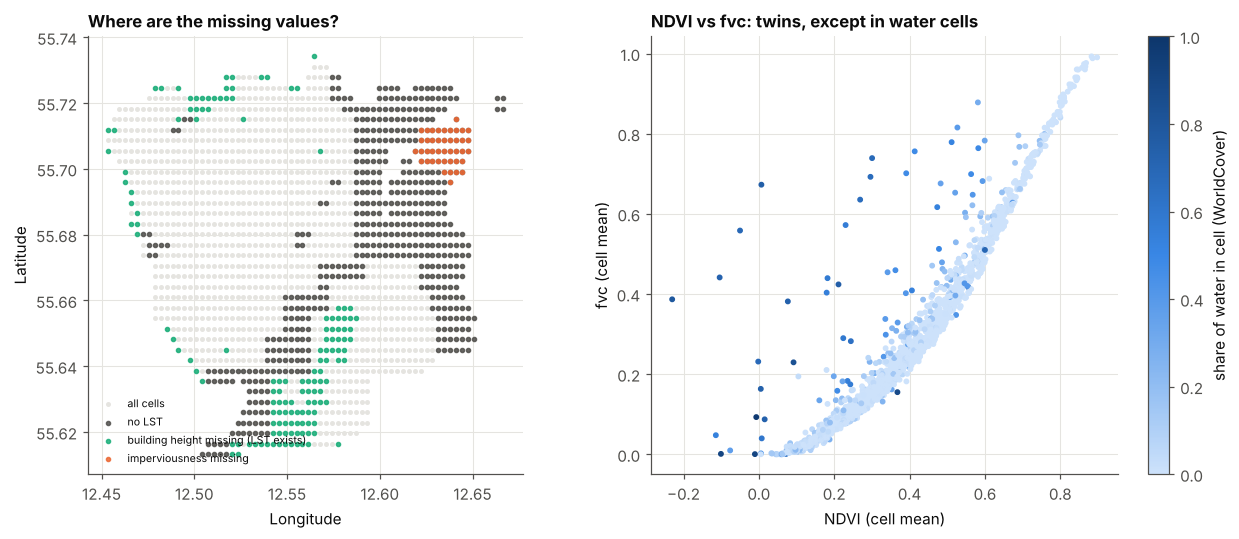

water share 0.00-0.05: n=1362, r(NDVI, fvc) = 0.98
water share 0.05-0.20: n= 131, r(NDVI, fvc) = 0.98
water share 0.20-1.00: n= 111, r(NDVI, fvc) = 0.65


In [7]:
rows = []
for c in ["fvc_mean", "imd_2024_pct_mean", "imd_2021_pct_mean", "ndvi_mean"]:
    m = df[c].isna()
    rows.append({
        "variable": c, "NaN": int(m.sum()),
        "of which water share ≥ 0.5": int((df.loc[m, "share_wc_water"] >= 0.5).sum()),
        "of which pure water cells (≥ 0.99)": int((df.loc[m, "share_wc_water"] >= 0.99).sum()),
        "of which few pixels (≤ 10)": int((df.loc[m, "n_pixels_10m"] <= 10).sum()),
        "of which with LST": int((m & df[TARGET].notna()).sum()),
    })
display(pd.DataFrame(rows).set_index("variable"))

m_fvc = df["fvc_mean"].isna() & df["ndvi_mean"].notna()
print(f"\nCells where fvc is missing but NDVI exists: {int(m_fvc.sum())}; of which NDVI < 0.06: {int((m_fvc & (df['ndvi_mean'] < 0.06)).sum())}")
print("(A hint that fvc may only be defined for pixels above an NDVI threshold. A hypothesis only, not confirmed.)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
ax.scatter(df[LON], df[LAT], s=5, color=GRID, label="all cells")
for mask, col, lab in [
    (df[TARGET].isna(), MUTED, "no LST"),
    (df[BBH].isna() & df[TARGET].notna(), AQUA, "building height missing (LST exists)"),
    (df["imd_2024_pct_mean"].isna(), ORANGE, "imperviousness missing"),
]:
    ax.scatter(df.loc[mask, LON], df.loc[mask, LAT], s=7, color=col, label=lab, alpha=0.85)
ax.set_aspect(1 / np.cos(np.deg2rad(df[LAT].mean())))
ax.set_title("Where are the missing values?")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(fontsize=7, loc="lower left", frameon=False)

ax = axes[1]
ok = df[["ndvi_mean", "fvc_mean", "share_wc_water"]].dropna()
sc = ax.scatter(ok["ndvi_mean"], ok["fvc_mean"], c=ok["share_wc_water"], cmap=SEQ, s=8, vmin=0, vmax=1)
plt.colorbar(sc, ax=ax, label="share of water in cell (WorldCover)")
ax.set_xlabel("NDVI (cell mean)"); ax.set_ylabel("fvc (cell mean)")
ax.set_title("NDVI vs fvc: twins, except in water cells")
plt.tight_layout(); plt.show()

for lo, hi in [(0, 0.05), (0.05, 0.2), (0.2, 1.01)]:
    sub = ok[(ok["share_wc_water"] >= lo) & (ok["share_wc_water"] < hi)]
    print(f"water share {lo:.2f}-{min(hi, 1):.2f}: n={len(sub):4d}, r(NDVI, fvc) = {sub[['ndvi_mean', 'fvc_mean']].corr().iloc[0, 1]:.2f}")

**How to read 2.3** (from the data, not from the provider):

* If the gaps in imperviousness and fvc are concentrated in *water cells without LST*, they disappear by themselves once we work with the 1,161 cells. The problem is then far smaller than the numbers for the whole table suggest.
* The drop in r(NDVI, fvc) in cells with water suggests that the two "duplicates" are not duplicates everywhere. One possible mechanism (**a hypothesis, not confirmed**): the NDVI mean includes water pixels (negative values), whereas fvc is a mean only over pixels *with a value*. This is exactly the kind of question the provider can answer.

### 2.4 Are the gaps in X linked to the gaps in LST?

**Intuition.** If the same cells lack both LST and an x-variable, there is probably one common cause (here: water), and the x-gaps then disappear by themselves when we only use cells with LST. We test this with a cross-tabulation per variable and **Fisher's exact test** (H0: being missing in x is independent of being missing in LST). An *odds ratio* above 1 means the x-gap occurs more often together with missing LST.

In [8]:
from scipy.stats import fisher_exact

no_lst = df[TARGET].isna()
rows = []
for c in ["ndvi_mean", "fvc_mean", "imd_2024_pct_mean", "tcd_2023_pct_mean", BBH]:
    m = df[c].isna()
    tab = [[int((m & no_lst).sum()), int((m & ~no_lst).sum())], [int((~m & no_lst).sum()), int((~m & ~no_lst).sum())]]
    odds, pval = fisher_exact(tab)
    rows.append({"variable": c, "NaN": int(m.sum()), "of which without LST": tab[0][0],
                 "% of NaN without LST": round(100 * tab[0][0] / max(m.sum(), 1)),
                 "% without LST among non-NaN": round(100 * no_lst[~m].mean()),
                 "odds ratio": round(odds, 2), "p (Fisher)": pval})
display(pd.DataFrame(rows).set_index("variable"))

core = ["ndvi_mean", "fvc_mean", "imd_2024_pct_mean", "tcd_2023_pct_mean"]
any_core = df[core].isna().any(axis=1)
print("\nNaN in NDVI/fvc/imperviousness/tree cover (row-wise) vs. LST missing:")
display(pd.crosstab(any_core.rename("NaN in at least one of the four"), no_lst.rename("LST missing")))

print("Share of cells without LST by water share (WorldCover):")
bins = pd.cut(df["share_wc_water"], [-0.01, 0, 0.05, 0.2, 0.5, 0.99, 1.0])
display(df.groupby(bins, observed=True)[TARGET].apply(lambda s_: round(s_.isna().mean(), 2)).to_frame("share without LST"))

,NaN,of which without LST,% of NaN without LST,% without LST among non-NaN,odds ratio,p (Fisher)
variable,,,,,,
ndvi_mean,6,4,67,30,4.58,7.431631e-02
fvc_mean,67,65,97,28,84.65,1.832156e-32
imd_2024_pct_mean,42,42,100,29,inf,6.678175e-23
tcd_2023_pct_mean,1,0,0,31,0.00,1.000000e+00
bbh_mean_where_built_m,324,186,57,24,4.26,1.588625e-29



NaN in NDVI/fvc/imperviousness/tree cover (row-wise) vs. LST missing:


LST missing,False,True
NaN in at least one of the four,,
False,1159,445
True,2,65


Share of cells without LST by water share (WorldCover):


,share without LST
share_wc_water,
"(-0.01, 0.0]",0.12
"(0.0, 0.05]",0.54
"(0.05, 0.2]",0.77
"(0.2, 0.5]",0.69
"(0.5, 0.99]",0.82
"(0.99, 1.0]",1.00


**How to read 2.4.** If almost all x-gaps are also LST gaps (high "% of NaN without LST", low p), they follow the same cells. If the share without LST rises sharply with water share, water is an obvious common explanation (**our interpretation of the pattern, not confirmed by the provider**). The reverse does not hold: many cells lack LST without lacking x. For building height the association mostly arises because cells without buildings are common in water cells (see 2.2).

### 2.5 Imperviousness 2021 vs 2024
The dataset has two vintages. LST is from June 2023, so 2021 and 2024 lie on either side. Are they so similar that we can safely use just one?

In [9]:
d = df[["imd_2021_pct_mean", "imd_2024_pct_mean"]].dropna()
diff = (d["imd_2024_pct_mean"] - d["imd_2021_pct_mean"]).abs()
print(f"r(2021, 2024) = {d.corr().iloc[0, 1]:.3f}; cells with a difference > 20 percentage points: {int((diff > 20).sum())}; > 40: {int((diff > 40).sum())}")
print("We use 2024 by default (as in the EDA). Switch to 2021 in FEATURES to test sensitivity.")

r(2021, 2024) = 0.996; cells with a difference > 20 percentage points: 10; > 40: 0
We use 2024 by default (as in the EDA). Switch to 2021 in FEATURES to test sensitivity.


### 2.6 Strategies for missing data: the function

Five options (see `STRATEGIES` in the configuration). All are **fitted on train only** (median and imputer), and the same rules are applied to test. The function is called both here and in the sensitivity analysis in Part 6.

In [10]:
def apply_missing_strategy(train, test, features, strategy):
    """Returns (train, test, features) after the chosen treatment of missing values."""
    train, test, feats = train.copy(), test.copy(), list(features)
    if strategy == "structural_zero":
        for d_ in (train, test):
            d_[BBH] = d_[BBH].fillna(0.0)
        train, test = train.dropna(subset=feats), test.dropna(subset=feats)
    elif strategy == "complete_case":
        train, test = train.dropna(subset=feats), test.dropna(subset=feats)
    elif strategy == "drop_bbh":
        feats.remove(BBH)
        train, test = train.dropna(subset=feats), test.dropna(subset=feats)
    elif strategy == "median_all":
        med = train[feats].median()
        train[feats], test[feats] = train[feats].fillna(med), test[feats].fillna(med)
    elif strategy == "iterative":
        for d_ in (train, test):
            d_[BBH] = d_[BBH].fillna(0.0)
        imp = IterativeImputer(random_state=RANDOM_STATE, max_iter=20).fit(train[feats])
        train[feats], test[feats] = imp.transform(train[feats]), imp.transform(test[feats])
    else:
        raise ValueError(strategy)
    return train.reset_index(drop=True), test.reset_index(drop=True), feats

## Part 3. Spatial split: train and test

**Intuition.** If we shuffle cells randomly, test cells sit right next to training cells with almost the same values, and the model "cheats" without knowing it. We therefore hold out a **geographic stretch**: the easternmost 20% of the LST cells (as in the group's random forest, cf. EDA impl. 4). Inside train we again use geographic blocks as cross-validation folds.

**Rule for the whole notebook:** scaler, imputer, PCA, varimax and all feature-selection steps are fitted on **train**. We touch the test set only at the very end.

Cut at longitude 12.5774: train = 950, test = 211


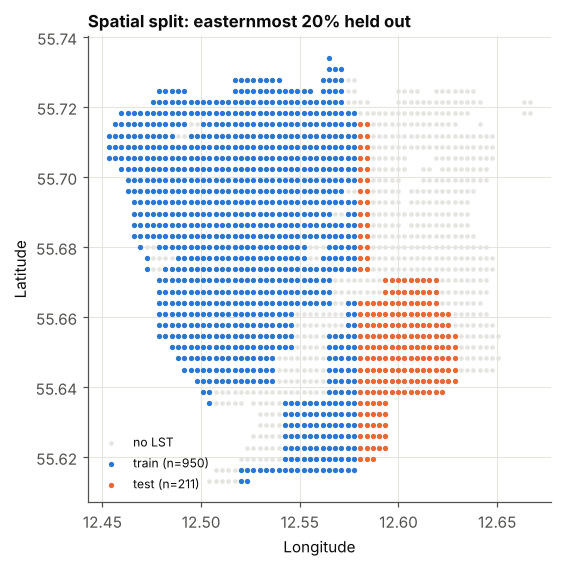

In [11]:
cut = lst_df[LON].quantile(1 - TEST_FRACTION)
is_test = lst_df[LON] > cut
train_raw, test_raw = lst_df[~is_test].reset_index(drop=True), lst_df[is_test].reset_index(drop=True)
print(f"Cut at longitude {cut:.4f}: train = {len(train_raw)}, test = {len(test_raw)}")

def make_splits(train_frame, n_folds=N_FOLDS):
    """Spatial folds: equal-sized blocks along longitude. Returns a list of (train_idx, val_idx)."""
    groups = pd.qcut(train_frame[LON].rank(method="first"), n_folds, labels=False)
    return list(GroupKFold(n_splits=n_folds).split(train_frame, groups=groups)), groups

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(df[LON], df[LAT], s=4, color=GRID, label="no LST")
ax.scatter(train_raw[LON], train_raw[LAT], s=6, color=BLUE, label=f"train (n={len(train_raw)})")
ax.scatter(test_raw[LON], test_raw[LAT], s=6, color=ORANGE, label=f"test (n={len(test_raw)})")
ax.set_aspect(1 / np.cos(np.deg2rad(df[LAT].mean())))
ax.set_title("Spatial split: easternmost 20% held out")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.show()

### Apply the chosen strategy (`MISSING_STRATEGY`)

In [12]:
train, test, feats = apply_missing_strategy(train_raw, test_raw, FEATURES, MISSING_STRATEGY)
print(f"Strategy: {MISSING_STRATEGY} – {STRATEGIES[MISSING_STRATEGY]}")
print(f"Train: {len(train_raw)} -> {len(train)} rows | Test: {len(test_raw)} -> {len(test)} rows | Features: {len(feats)}")
print("NaN left in train features:", int(train[feats].isna().sum().sum()))

splits, fold_groups = make_splits(train)
y_tr, y_te = train[TARGET], test[TARGET]

Strategy: structural_zero – Building height: empty -> 0 (no buildings; tested in Part 2). Other rows with NaN are dropped.
Train: 950 -> 948 rows | Test: 211 -> 211 rows | Features: 13
NaN left in train features: 0


## Part 4. Factor analysis (follows the FA sheet: KMO → PCA → varimax → reliability)

**Intuition.** If several questions in a questionnaire are always answered alike, they probably measure the same thing underneath. We look for a few "underlying axes" that summarise many variables. **Important:** LST is *not* included. We only look for structure among the *predictors*.

**Terminology and what this analysis can and cannot claim.** The FA sheet is called *Factor Analysis*, but the code is **PCA + varimax rotation**. A true factor analysis models only the *shared* variance, whereas PCA uses all variance (Field et al. 2012, §17.3.6); we therefore write "PCA with varimax" and add a check against a true common-factor solution in 4.5. The course presents factor analysis as a way to measure *latent, reflective constructs* behind questionnaire items (Karam 2026a), and Park et al. (2022) is an example of that use (multi-item scales validated with CFA, loadings and VIF). **Our 13 variables are physical measurements of a place, not items that reflect an attitude.** The axes we find are therefore *summaries of how land-surface variables co-vary*, not hidden causes, and Cronbach's alpha is a descriptive consistency measure here, not scale validation. Field et al. (2012) also remind us that PCA conclusions apply to the sample analysed (here: Copenhagen land cells with LST on one morning).

### 4.1 Correlation matrix and skewness (sheet: Part 1)

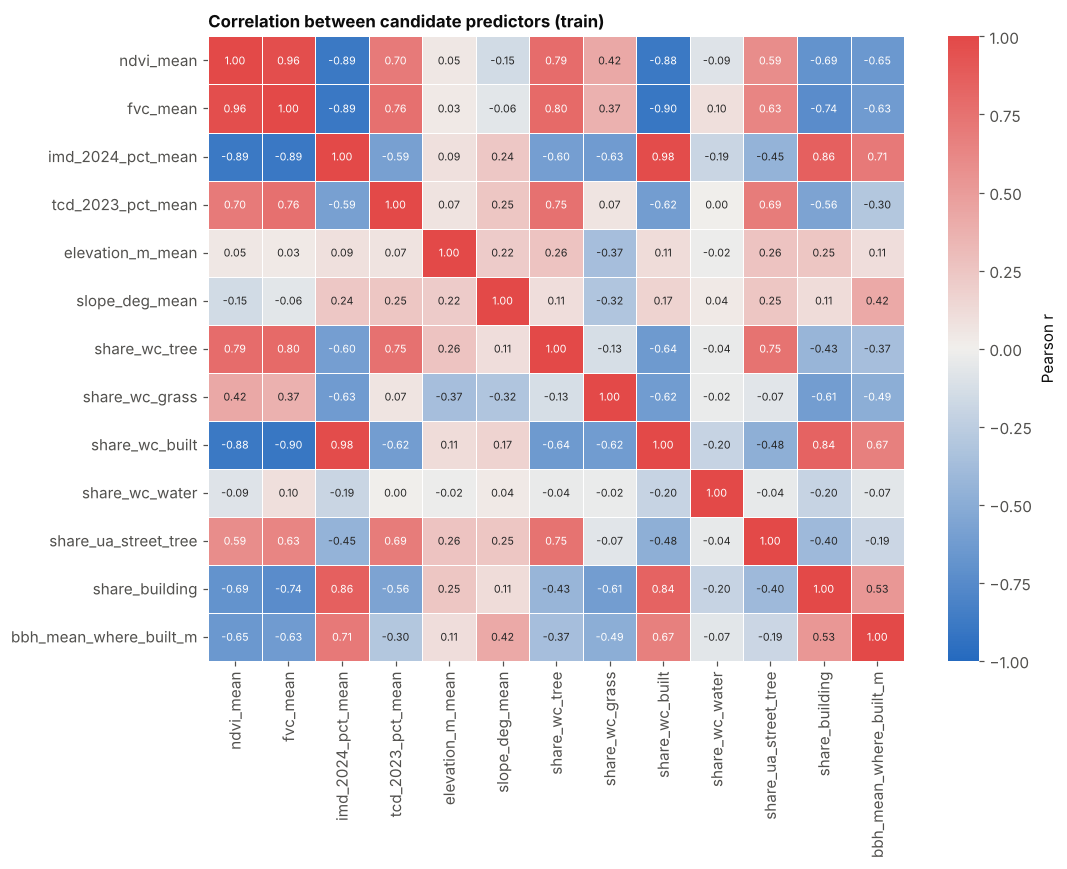

,skewness,share of zeros
share_wc_water,6.01,0.85
tcd_2023_pct_mean,2.37,0.25
share_ua_street_tree,2.16,0.14
share_wc_grass,2.14,0.15
share_wc_tree,0.93,0.03
fvc_mean,0.87,0.00
slope_deg_mean,0.86,0.00
bbh_mean_where_built_m,0.45,0.13
elevation_m_mean,0.41,0.00
ndvi_mean,0.27,0.00


Most strongly correlated pairs (duplicate candidates, cf. EDA impl. 3):


r
imd_2024_pct_mean share_wc_built     0.98
ndvi_mean         fvc_mean           0.96
fvc_mean          share_wc_built    -0.90
                  imd_2024_pct_mean -0.89
ndvi_mean         imd_2024_pct_mean -0.89
                  share_wc_built    -0.88
imd_2024_pct_mean share_building     0.86
share_wc_built    share_building     0.84

Determinant of the correlation matrix: 1.27e-08 (close to 0 = near-linear dependence)

Pairs with |r| > 0.80 (Field et al.: candidates for removal; here 8 pairs):


r
imd_2024_pct_mean share_wc_built     0.98
ndvi_mean         fvc_mean           0.96
fvc_mean          share_wc_built    -0.90
                  imd_2024_pct_mean -0.89
ndvi_mean         imd_2024_pct_mean -0.89
                  share_wc_built    -0.88
imd_2024_pct_mean share_building     0.86
share_wc_built    share_building     0.84

Variables whose largest |r| with any other variable is below 0.30 (Field et al.: too little in common): ['share_wc_water']


In [13]:
Xtr_raw = train[feats]
corr = Xtr_raw.corr(method="pearson")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidth=0.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation between candidate predictors (train)")
plt.tight_layout(); plt.show()

skew = Xtr_raw.skew().sort_values(ascending=False).round(2).rename("skewness")
zeros = (Xtr_raw == 0).mean().round(2).rename("share of zeros")
display(pd.concat([skew, zeros.reindex(skew.index)], axis=1))

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
top_pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(2)
print("Most strongly correlated pairs (duplicate candidates, cf. EDA impl. 3):")
display(top_pairs.to_frame("r"))
print("Determinant of the correlation matrix:", f"{np.linalg.det(corr.values):.2e}", "(close to 0 = near-linear dependence)")

# Field et al. (2012, §17.4.2): look for correlations that are too low (< .3 with all others) or too high (> .8)
absr = corr.abs().where(~np.eye(len(corr), dtype=bool))
too_high = pairs[pairs.abs() > 0.80].sort_values(key=np.abs, ascending=False).round(2)
print(f"\nPairs with |r| > 0.80 (Field et al.: candidates for removal; here {len(too_high)} pairs):")
display(too_high.to_frame("r"))
print("Variables whose largest |r| with any other variable is below 0.30 (Field et al.: too little in common):",
      list(absr.max()[absr.max() < 0.30].index) or "none")

**How to read it.**

* The four WorldCover shares (`tree`, `grass`, `built`, `water`) are shares of the same cell, so if one rises, the others fall. This is called *compositional data* and gives mechanical correlation (we can check the sum ourselves: `train[[...]].sum(axis=1)`).
* **Result of the screening (see output above).** Eight pairs exceed |r| = .80: six among NDVI, fvc, imperviousness and built-up share (|r| from .88 to .98) and two involving building share (with imperviousness .86, with built-up .84). Only `share_wc_water` has no correlation above .30 with any other variable, which matches its very low MSA in 4.2 (it is zero in 85% of cells). The determinant is 1.3e-08, i.e. below the 0.00001 guideline, so the full set of 13 is multicollinear in Field et al.'s sense. This is not a problem for the PCA itself (it is a way of handling correlated variables), but it matters for a linear regression (Part 5).
* **Field et al. (2012, §17.4.2)** give two screening rules for the correlation matrix: variables that correlate below about .3 with everything else have little in common with the rest, and correlations above .8 point to multicollinearity, with the determinant of R expected to exceed 0.00001. Our determinant is far below that, which is expected here because the water, tree, grass and built-up shares add up to a whole, and NDVI/fvc and imperviousness/built-up are near-duplicates. Field et al. also warn that dropping one variable of each r > .8 pair does not always remove the real cause of multicollinearity (Rockwell, 1975, as cited there), so we do not stop at the pair list: we also look at VIF in Part 5.4 and at grouped importance.
* Very skewed variables (many zeros) weigh differently in a PCA than symmetric ones. Standardisation removes *scale*, not *skewness*. If we want to test a `log1p` transformation of e.g. tree cover, it is a separate choice that we should document.

### 4.2 Standardisation and KMO (sheet: Part 1, "The Kaiser-Meyer-Olkin test")

KMO answers: *"Is there any shared structure to find at all?"* The sheet uses the rule of thumb that KMO below 0.6 suggests factor analysis is not suitable. Besides the overall KMO we compute a per-variable **MSA** (measure of sampling adequacy). A variable with low MSA is poorly related to the others and adds "noise" to the analysis. The sheet itself asks *"What can we do when KMO < 0.6?"*: one answer is to leave out the weakest variables.

In [14]:
def drop_low_msa(X_df, threshold, min_cols=3):
    """Iteratively removes the variable with the lowest MSA as long as it is below the threshold."""
    cols, log = list(X_df.columns), []
    while len(cols) > min_cols:
        Z = StandardScaler().fit_transform(X_df[cols])
        msa, kmo = calculate_kmo(Z)
        worst = int(np.argmin(msa))
        if msa[worst] >= threshold:
            break
        log.append({"dropped": cols[worst], "MSA": round(float(msa[worst]), 2), "overall KMO before": round(float(kmo), 3)})
        cols.pop(worst)
    return cols, log

Z_all = StandardScaler().fit_transform(Xtr_raw)
msa_all, kmo_all_model = calculate_kmo(Z_all)
chi2, p_bart = calculate_bartlett_sphericity(Z_all)
print(f"Overall KMO (all {len(feats)} variables): {kmo_all_model:.3f}")
print(f"Bartlett's test: chi2 = {chi2:.0f}, p = {p_bart:.3g}  (H0: the correlation matrix is the identity matrix = no structure)")
display(pd.Series(msa_all, index=feats, name="MSA").round(2).sort_values().to_frame())

fa_cols, msa_log = drop_low_msa(Xtr_raw, MSA_MIN)
print("\nDropped due to MSA <", MSA_MIN, ":", msa_log if msa_log else "none")
Z_fa_raw = Xtr_raw[fa_cols]
scaler_fa = StandardScaler().fit(Z_fa_raw)
X_fa = scaler_fa.transform(Z_fa_raw)
print(f"Overall KMO after dropping ({len(fa_cols)} variables): {calculate_kmo(X_fa)[1]:.3f}")

Overall KMO (all 13 variables): 0.771
Bartlett's test: chi2 = 17125, p = 0  (H0: the correlation matrix is the identity matrix = no structure)


,MSA
share_wc_water,0.09
share_wc_grass,0.55
elevation_m_mean,0.56
slope_deg_mean,0.67
share_wc_tree,0.69
ndvi_mean,0.77
share_wc_built,0.77
fvc_mean,0.81
imd_2024_pct_mean,0.82
share_building,0.87



Dropped due to MSA < 0.5 : [{'dropped': 'share_wc_water', 'MSA': 0.09, 'overall KMO before': 0.771}]
Overall KMO after dropping (12 variables): 0.770


**Remember:** Bartlett's test is almost always rejected with many rows (n in the hundreds), even for weak structure. KMO and MSA are therefore more informative here. A variable with MSA below 0.5 (typically a near-constant variable, e.g. many water zeros) is not "bad"; it just does not hang together with the rest and is left out *of the factor analysis*, not necessarily of the models.

### 4.3 PCA and how many components? (sheet: Part 2 + kneed from the FS sheet)

**Intuition.** Imagine a cloud of points in 12 dimensions. PCA finds the direction in which the cloud is longest (PC1), then the second longest perpendicular to it (PC2), and so on. The first few directions capture most of the spread.

There are several rules of thumb for the number of components, and they do not always agree. We show them all:

      eigenvalue  share of variance  cumulative
PC1        6.641              0.553       0.553
PC2        2.415              0.201       0.754
PC3        1.006              0.084       0.838
PC4        0.645              0.054       0.891
PC5        0.385              0.032       0.923
PC6        0.292              0.024       0.948
PC7        0.240              0.020       0.968
PC8        0.219              0.018       0.986
PC9        0.081              0.007       0.993
PC10       0.055              0.005       0.997
PC11       0.025              0.002       0.999
PC12       0.009              0.001       1.000


,number of components
Kaiser (eigenvalue > 1),3
Parallel analysis (95th percentile),2
"Elbow, sheet's max-distance",3
"Elbow, kneed (variance)",3
"Elbow, kneed (cumulative)",4
At least 80% variance,3



Chosen number of components K = 3 (cumulative variance: 83.8%)


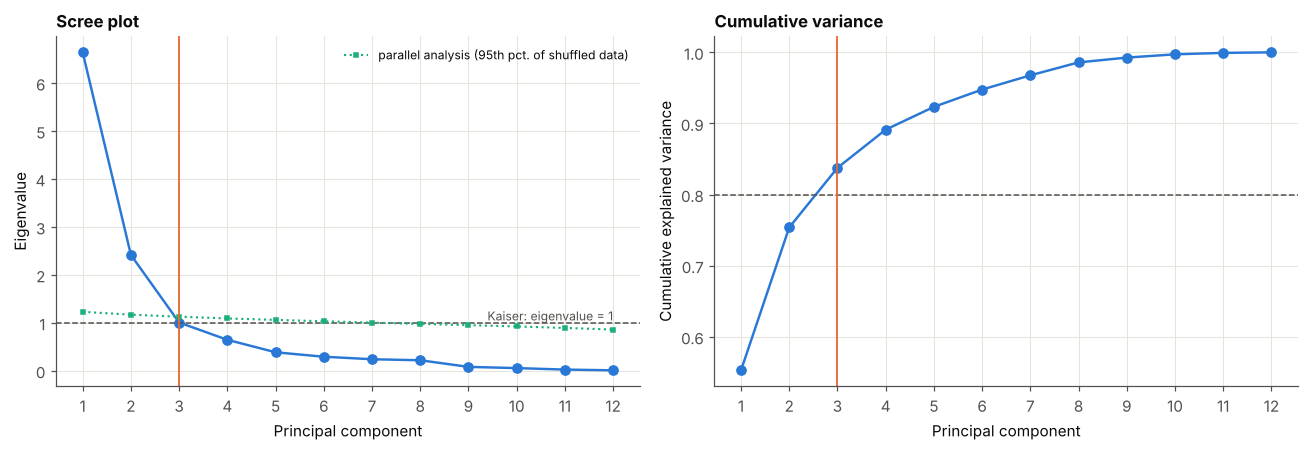

In [15]:
p = X_fa.shape[1]
pca = PCA(n_components=p).fit(X_fa)
ev_ratio, eigvals = pca.explained_variance_ratio_, pca.explained_variance_
cum = np.cumsum(ev_ratio)
print(pd.DataFrame({"eigenvalue": eigvals.round(3), "share of variance": ev_ratio.round(3), "cumulative": cum.round(3)},
                   index=[f"PC{i+1}" for i in range(p)]).to_string())

def elbow_max_distance(y):
    """The sheet's method: the point with the largest distance to the line between the first and last point."""
    x = np.arange(1, len(y) + 1)
    start, end = np.array([x[0], y[0]]), np.array([x[-1], y[-1]])
    v = (end - start) / np.linalg.norm(end - start)
    dist = [np.linalg.norm((np.array([x[i], y[i]]) - start) - np.dot(np.array([x[i], y[i]]) - start, v) * v) for i in range(len(x))]
    return int(x[int(np.argmax(dist))])

def parallel_analysis(X, reps, q=95, seed=RANDOM_STATE):
    """Horn's parallel analysis (Field et al. 2012, §17.3.8): eigenvalues of correlation matrices of data in which every column
    has been shuffled independently (same marginal distributions, no relations). Keep components whose real eigenvalue exceeds
    the q-th percentile of the shuffled ones."""
    rng = np.random.default_rng(seed)
    sims = np.empty((reps, X.shape[1]))
    for r in range(reps):
        Xp = np.column_stack([rng.permutation(X[:, j]) for j in range(X.shape[1])])
        sims[r] = np.sort(np.linalg.eigvalsh(np.corrcoef(Xp, rowvar=False)))[::-1]
    return np.percentile(sims, q, axis=0)

obs_eig = np.sort(np.linalg.eigvalsh(np.corrcoef(X_fa, rowvar=False)))[::-1]
pa_threshold = parallel_analysis(X_fa, PARALLEL_REPS)
k_parallel = int(np.argmin(np.r_[obs_eig > pa_threshold, False]))   # number of leading components that beat chance
k_kaiser = int((eigvals > 1).sum())
k_elbow = elbow_max_distance(ev_ratio)
kn1 = KneeLocator(np.arange(1, p + 1), ev_ratio, S=1.0, curve="convex", direction="decreasing").knee
kn2 = KneeLocator(np.arange(1, p + 1), cum, S=1.0, curve="concave", direction="increasing").knee
k_80 = int(np.argmax(cum >= 0.80) + 1)
rules = pd.Series({"Kaiser (eigenvalue > 1)": k_kaiser, "Parallel analysis (95th percentile)": k_parallel, "Elbow, sheet's max-distance": k_elbow,
                   "Elbow, kneed (variance)": kn1, "Elbow, kneed (cumulative)": kn2, "At least 80% variance": k_80}, name="number of components")
display(rules.to_frame())

K = int(N_COMPONENTS or max(1, k_kaiser))
print(f"\nChosen number of components K = {K} (cumulative variance: {cum[K-1]:.1%})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(1, p + 1)
axes[0].plot(x, eigvals, marker="o", color=BLUE, lw=1.6)
axes[0].axhline(1, color=MUTED, lw=1, ls="--"); axes[0].text(p, 1.05, "Kaiser: eigenvalue = 1", ha="right", fontsize=8, color=MUTED)
axes[0].plot(x, pa_threshold, color=AQUA, lw=1.4, ls=":", marker="s", ms=3, label="parallel analysis (95th pct. of shuffled data)")
axes[0].legend(frameon=False, fontsize=8)
axes[0].axvline(K, color=ORANGE, lw=1.2); axes[0].set_xticks(x)
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Eigenvalue"); axes[0].set_title("Scree plot")
axes[1].plot(x, cum, marker="o", color=BLUE, lw=1.6)
axes[1].axhline(0.8, color=MUTED, lw=1, ls="--"); axes[1].axvline(K, color=ORANGE, lw=1.2); axes[1].set_xticks(x)
axes[1].set_xlabel("Principal component"); axes[1].set_ylabel("Cumulative explained variance"); axes[1].set_title("Cumulative variance")
plt.tight_layout(); plt.show()

**Which rule do we follow, and why? (the sheet's question).** The rules do not agree: Kaiser, the sheet's elbow, kneed on the variance curve and the 80% target say **3**; kneed on the cumulative curve says 4; **parallel analysis says 2**. Field et al. (2012, §17.3.8) rank the rules as Kaiser worst (it tends to keep too many components) and parallel analysis best, and Karam (2026a) and Field et al. (2012) accept the scree plot when n > 200 (we have ~950 cells). Two facts argue for a cautious reading:

* The third eigenvalue is **1.006**, only just above Kaiser's threshold of 1 and clearly below the chance level from parallel analysis (about 1.1), so PC3 is a *borderline* component, not a clear one.
* PC3 is nevertheless interpretable (slope and building height, see 4.5), it brings the total to 83.8% (above the 80% target), and Field et al. note that when factor scores are used as regression inputs it is better to keep too many than too few components.

**Our decision: K = 3 for describing the structure**, with the caveat that the third axis is weak and that a two-axis solution (greenness/imperviousness and elevation/grass) is also defensible. K is **not** what decides the modelling later: in Part 5.5b we tune the number of components by cross-validation (Géron, ch. 8). Change `N_COMPONENTS` in the configuration to test alternatives.

### 4.4 Scores in 2D, coloured by LST (sheet: Part 2, scatter plot)
Each dot is a cell. LST is used **only for the colour**, not to build the axes.

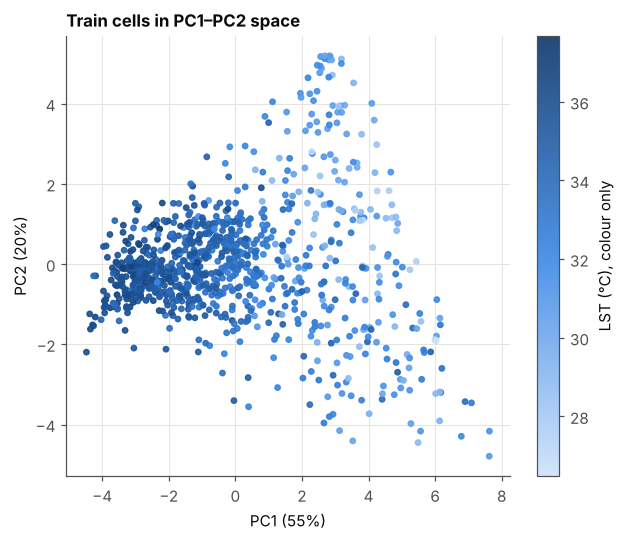

In [16]:
scores = pca.transform(X_fa)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sc = ax.scatter(scores[:, 0], scores[:, 1], c=y_tr, cmap=SEQ, s=12, alpha=0.9)
plt.colorbar(sc, ax=ax, label="LST (°C), colour only")
ax.set_xlabel(f"PC1 ({ev_ratio[0]:.0%})"); ax.set_ylabel(f"PC2 ({ev_ratio[1]:.0%})")
ax.set_title("Train cells in PC1–PC2 space")
plt.show()

### 4.5 Varimax rotation and loadings (sheet: Part 3; FS sheet: varimax heatmaps)

**Intuition.** The PC axes are mathematically fine but often hard to name, because every variable "loads a little" on many axes. Varimax *rotates* the axes, without changing the total explained variance, so that each variable preferably belongs to one axis. Like rotating a map so that cities lie more clearly on either side of a line.

`loading = components_ · √eigenvalue` (exactly as in the sheet) is the correlation between a variable and a component.

Explained variance: total before rotation = 83.8% | after rotation (sum of squared loadings / number of variables) = 83.8%
(Varimax changes the distribution between the axes, not the total.)


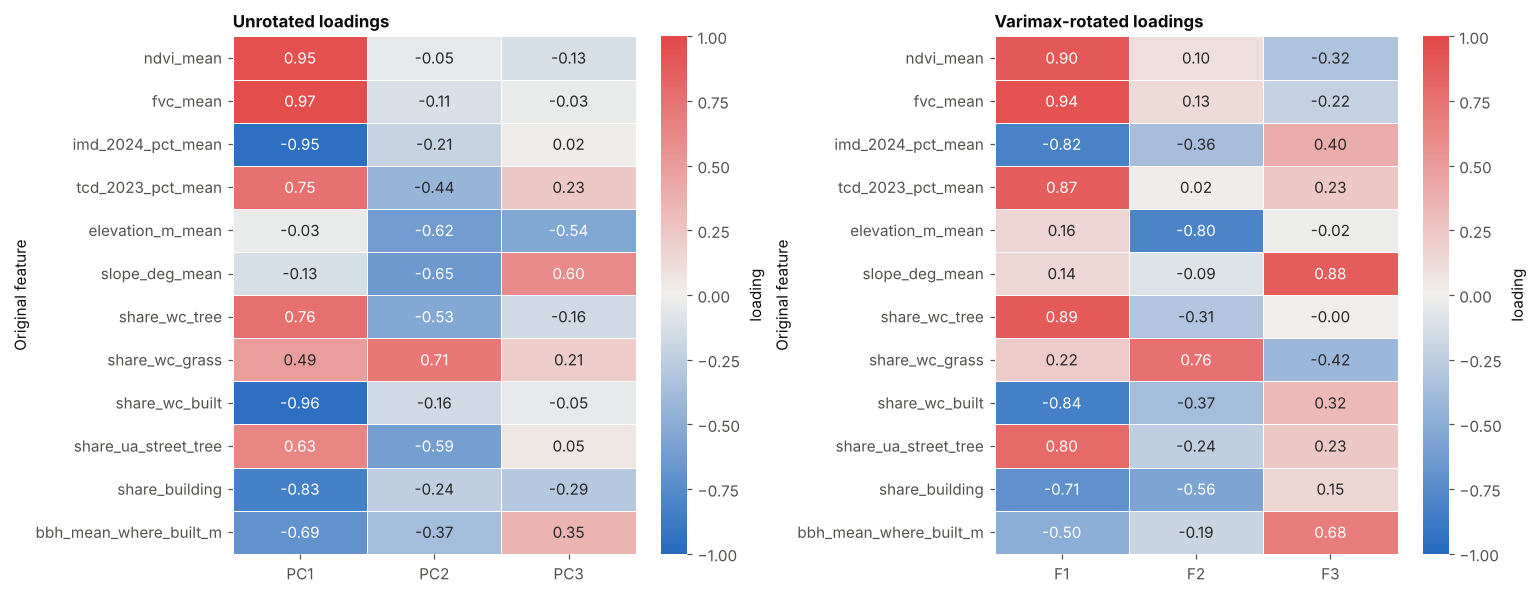

,belongs to,largest |loading|,clear (≥ cutoff)
fvc_mean,F1,0.94,True
ndvi_mean,F1,0.90,True
share_wc_tree,F1,0.89,True
tcd_2023_pct_mean,F1,0.87,True
share_wc_built,F1,0.84,True
imd_2024_pct_mean,F1,0.82,True
share_ua_street_tree,F1,0.80,True
share_building,F1,0.71,True
elevation_m_mean,F2,0.80,True
share_wc_grass,F2,0.76,True


Cut-off sensitivity (12 variables in total; Karam 2026a uses 0.3, Field et al. 2012, §17.3.9.2 recommend interpreting > 0.4):


,|loading| >= 0.3,|loading| >= 0.4,|loading| >= 0.5
variables clearly on one axis,12,12,12


Cross-loadings (a second loading >= cut-off):
{'share_wc_grass': ['F2', 'F3'], 'share_building': ['F1', 'F2'], 'bbh_mean_where_built_m': ['F1', 'F3']}


In [17]:
pcaK = PCA(n_components=K).fit(X_fa)
loadings = pcaK.components_.T * np.sqrt(pcaK.explained_variance_)
rotator = Rotator(method="varimax")
rot_loadings = rotator.fit_transform(loadings)

cols_k = [f"F{i+1}" for i in range(K)]
L_unrot = pd.DataFrame(loadings, index=fa_cols, columns=[f"PC{i+1}" for i in range(K)])
L_rot = pd.DataFrame(rot_loadings, index=fa_cols, columns=cols_k)

print("Explained variance: total before rotation =", f"{pcaK.explained_variance_ratio_.sum():.1%}",
      "| after rotation (sum of squared loadings / number of variables) =", f"{(rot_loadings ** 2).sum() / len(fa_cols):.1%}")
print("(Varimax changes the distribution between the axes, not the total.)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, M, ttl in [(axes[0], L_unrot, "Unrotated loadings"), (axes[1], L_rot, "Varimax-rotated loadings")]:
    sns.heatmap(M, annot=True, fmt=".2f", cmap=DIV, vmin=-1, vmax=1, center=0, linewidth=0.5, ax=ax, cbar_kws={"label": "loading"})
    ax.set_title(ttl); ax.set_ylabel("Original feature")
plt.tight_layout(); plt.show()

assign = L_rot.abs().idxmax(axis=1).rename("belongs to")
summary = pd.concat([assign, L_rot.abs().max(axis=1).round(2).rename("largest |loading|")], axis=1)
summary["clear (≥ cutoff)"] = summary["largest |loading|"] >= LOADING_CUTOFF
display(summary.sort_values(["belongs to", "largest |loading|"], ascending=[True, False]))

# Loading cut-off sensitivity: slides 0.3, Stevens/Field 0.4 (our choice), our earlier 0.5
cut_tab = pd.DataFrame({f"|loading| >= {c}": [int((summary["largest |loading|"] >= c).sum())] for c in (0.3, 0.4, 0.5)}, index=["variables clearly on one axis"])
print(f"Cut-off sensitivity ({len(fa_cols)} variables in total; Karam 2026a uses 0.3, Field et al. 2012, §17.3.9.2 recommend interpreting > 0.4):")
display(cut_tab)
print("Cross-loadings (a second loading >= cut-off):")
cross = {v: [c for c in cols_k if abs(L_rot.loc[v, c]) >= LOADING_CUTOFF] for v in fa_cols}
print({v: c for v, c in cross.items() if len(c) > 1} or "none")

**Cut-off.** Karam (2026a) uses 0.3. Field et al. (2012, §17.3.9.2) note that 0.3 is the common convention, give Stevens' sample-size-dependent critical values (about 0.16 for n = 1,000, so with ~950 cells almost any loading above 0.2 is statistically distinguishable from zero) and say that the *substantive* importance is better judged on the squared loading, for which Stevens recommends |loading| > 0.4 (about 16% of the variable's variance). With ~950 cells significance is easy to reach, so we use **0.4** and show the 0.3/0.5 counts above.

### 4.5b Communalities and whether Kaiser's rule is trustworthy (Karam 2026a; Field et al. 2012, §17.3.5, §17.3.8)

The **communality** of a variable is the share of its variance that the K retained components reproduce (the sum of its squared loadings). In PCA we start at 1 for every variable, and after extraction it is below 1: it tells how much information the retained axes keep for that variable. The course states that Kaiser's eigenvalue-above-1 rule is only reliable when there are fewer than 30 variables **and** all communalities after extraction exceed .7, or when n > 250 **and** the mean communality is at least .6.

In [18]:
h2 = pd.Series((loadings ** 2).sum(axis=1), index=fa_cols, name="communality after extraction")
display(h2.sort_values().round(2).to_frame())
n_fa = len(X_fa)
cond_a = (len(fa_cols) < 30) and bool((h2 > 0.7).all())
cond_b = (n_fa > 250) and (h2.mean() >= 0.6)
print(f"Mean communality = {h2.mean():.2f}; lowest = {h2.min():.2f} ({h2.idxmin()}); n = {n_fa}")
print(f"Condition A (p < 30 and all communalities > .7): {cond_a}")
print(f"Condition B (n > 250 and mean communality >= .6): {cond_b}")
print("-> Kaiser's rule is", "acceptable under the course criteria" if (cond_a or cond_b) else "NOT justified by the course criteria; we rely on scree, parallel analysis and interpretability")

,communality after extraction
elevation_m_mean,0.67
bbh_mean_where_built_m,0.75
share_ua_street_tree,0.75
share_wc_grass,0.79
slope_deg_mean,0.80
tcd_2023_pct_mean,0.81
share_building,0.83
share_wc_tree,0.89
ndvi_mean,0.93
share_wc_built,0.94


Mean communality = 0.84; lowest = 0.67 (elevation_m_mean); n = 948
Condition A (p < 30 and all communalities > .7): False
Condition B (n > 250 and mean communality >= .6): True
-> Kaiser's rule is acceptable under the course criteria


**What the communalities tell us.** The three axes reproduce 84% of the variance on average (mean communality 0.84) and every variable keeps at least 67% (the lowest is elevation, 0.67). Karam's first condition (all communalities above .7 with fewer than 30 variables) is therefore *just* missed, because of elevation, but the second (n > 250 and mean communality of at least .6) is met, so by the course's own criteria Kaiser's rule is acceptable here. We still do not rely on it alone (see parallel analysis above).

### 4.5c Oblique rotation: do the axes correlate? (Field et al. 2012, §17.3.9)

Varimax forces the axes to be uncorrelated. Land-surface variables rarely behave that way (greener places are also less built up, and so on). Field et al. suggest running an **oblique** rotation as well: if the factors turn out to be (almost) uncorrelated, the orthogonal (varimax) solution is fine; if they correlate, the oblique solution is more realistic and varimax should be dropped. We use oblimin on the same K components.

Factor correlation matrix (oblimin):


,F1,F2,F3
F1,1.00,0.09,-0.09
F2,0.09,1.00,-0.32
F3,-0.09,-0.32,1.00


Largest absolute correlation between factors: 0.32


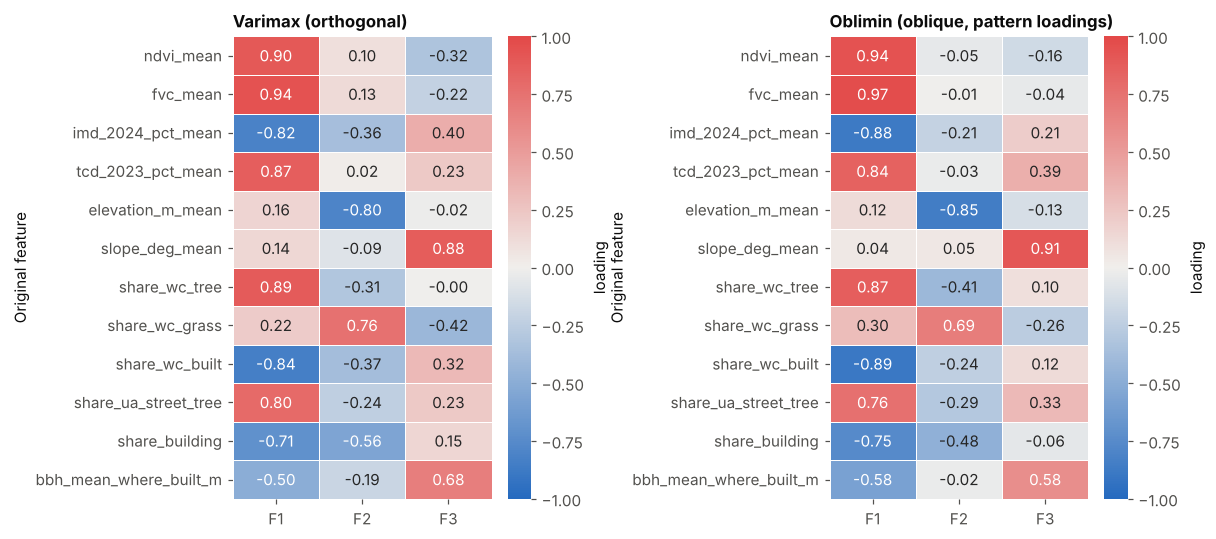

Same grouping of variables into axes under varimax and oblimin: True


In [19]:
rot_obl = Rotator(method=OBLIQUE_METHOD)
L_obl = pd.DataFrame(rot_obl.fit_transform(loadings), index=fa_cols, columns=cols_k)   # pattern loadings
phi = pd.DataFrame(rot_obl.phi_, index=cols_k, columns=cols_k)                       # factor correlations
print("Factor correlation matrix (oblimin):")
display(phi.round(2))
off = phi.values[np.triu_indices(K, 1)]
print(f"Largest absolute correlation between factors: {np.abs(off).max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, M, ttl in [(axes[0], L_rot, "Varimax (orthogonal)"), (axes[1], L_obl, f"{OBLIQUE_METHOD.capitalize()} (oblique, pattern loadings)")]:
    sns.heatmap(M, annot=True, fmt=".2f", cmap=DIV, vmin=-1, vmax=1, center=0, linewidth=0.5, ax=ax, cbar_kws={"label": "loading"})
    ax.set_title(ttl); ax.set_ylabel("Original feature")
plt.tight_layout(); plt.show()

# does the oblique solution assign variables to the same axes as varimax?
# (factor order/sign can differ, so we compare the grouping through the largest |loading|)
grp_v = L_rot.abs().idxmax(axis=1)
grp_o = L_obl.abs().idxmax(axis=1)
same_partition = all(((grp_v == grp_v[a]) == (grp_o == grp_o[a])).all() for a in fa_cols)
print("Same grouping of variables into axes under varimax and oblimin:", same_partition)

**What the oblique solution tells us.** The largest correlation between two factors is **0.32** (F2 and F3, i.e. the elevation/grass axis and the slope/building-height axis); F1 is almost uncorrelated with the others (|r| ≤ 0.09). Field et al. say to prefer the orthogonal solution if the factors are negligibly correlated and the oblique one if they are not. A correlation of .32 means about 10% shared variance, which is modest but not nothing. The oblimin solution puts every variable on the same axis as varimax does, so **the interpretation does not depend on the rotation**; the main difference is that oblimin shows somewhat cleaner loadings: the cross-loadings of `share_wc_grass` (F3: −.42 to −.26) and `share_building` (F2: −.56 to −.48) shrink, while `bbh_mean_where_built_m` stays split between F1 and F3 (−.58 / .58), so we should describe it as sitting between the two axes. We keep **varimax** for the factor scores we export (they are uncorrelated, which is convenient for a regression) and report oblimin as a robustness check. If the group wants to *interpret* the axes in the report, the oblique pattern loadings are the more honest description.

### 4.5d Check against a true common-factor solution (Field et al. 2012, §17.3.6)

PCA reproduces all variance, factor analysis only the shared variance. Field et al. (citing Stevens) note that with *fewer than 20 variables and low communalities* (< .4) the two can differ. We have 12 variables, so we check: do the communalities and the grouping change if we use a common-factor extraction (principal-axis factoring) instead of PCA?

In [20]:
def principal_axis(R, k, iters=200, tol=1e-6):
    """Principal-axis factoring: iterate communalities on the diagonal of R (only shared variance is modelled)."""
    h = 1 - 1 / np.diag(np.linalg.inv(R))          # start: squared multiple correlations
    for _ in range(iters):
        Rr = R.copy(); np.fill_diagonal(Rr, h)
        w, v = np.linalg.eigh(Rr); idx = np.argsort(w)[::-1][:k]
        L = v[:, idx] * np.sqrt(np.clip(w[idx], 0, None))
        h_new = (L ** 2).sum(axis=1)
        if np.abs(h_new - h).max() < tol:
            break
        h = h_new
    return L, h_new

L_paf, h_paf = principal_axis(np.corrcoef(X_fa, rowvar=False), K)
L_paf_rot = Rotator(method="varimax").fit_transform(L_paf)
cmp_h = pd.DataFrame({"PCA communality": h2, "common-factor communality": pd.Series(h_paf, index=fa_cols)}).round(2)
display(cmp_h)
grp_t = pd.DataFrame(L_paf_rot, index=fa_cols, columns=cols_k).abs().idxmax(axis=1)
same_true = all(((grp_v == grp_v[a]) == (grp_t == grp_t[a])).all() for a in fa_cols)
print("Same grouping of variables under PCA+varimax and principal-axis+varimax:", same_true,
      f"| largest communality difference: {(cmp_h.iloc[:, 0] - cmp_h.iloc[:, 1]).abs().max():.2f}")

,PCA communality,common-factor communality
ndvi_mean,0.93,0.93
fvc_mean,0.95,0.96
imd_2024_pct_mean,0.95,0.97
tcd_2023_pct_mean,0.81,0.75
elevation_m_mean,0.67,0.25
slope_deg_mean,0.80,0.52
share_wc_tree,0.89,0.95
share_wc_grass,0.79,0.79
share_wc_built,0.94,0.95
share_ua_street_tree,0.75,0.67


Same grouping of variables under PCA+varimax and principal-axis+varimax: True | largest communality difference: 0.42


**What the common-factor check tells us.** The grouping of variables into axes is identical, so the *story* does not depend on PCA vs factor analysis. The communalities, however, differ for some variables: elevation falls from 0.67 to 0.25 and slope from 0.80 to 0.52 when only shared variance is modelled, i.e. much of their PCA loading is their *own* variance, not variance shared with the other variables. This is the situation Field et al. warn about (fewer than 20 variables, some low communalities). The practical consequence: **F2 and F3 are weaker, more "single-variable" axes than F1**, which is also what their lower alpha values show in 4.6.

**Our task (interpretation).** For each rotated axis we look at which variables go together (same sign = move together, opposite sign = move in opposite directions). We then name each axis in terms of the *surface*, not the temperature. Variables below the cutoff do not clearly belong to any axis. We also note which variables load on more than one axis (cross-loadings); these deserve a comment.

**Caveat.** The signs of PCA axes are arbitrary (they can flip between runs). A wrong interpretation would be to call an axis "the cause of heat". The axes describe how the *surface variables* hang together, not what affects LST.

### 4.6 Reliability: Cronbach's alpha per axis (sheet: Part 4)

**Intuition.** If four questions are meant to measure "the same attitude", they should vary together. Alpha measures this: close to 1 = consistent; the sheet's thresholds: above 0.7 acceptable, 0.5–0.7 moderate, below 0.5 weak.

We make two changes relative to the sheet, both because alpha assumes that all items *point the same way* and weigh equally:
1. alpha is computed on **standardised** variables (the sheet uses raw values, where large numbers dominate),
2. variables with a **negative loading** are flipped (× −1) first. Otherwise NDVI (negative) and imperviousness (positive) would pull alpha down even though they are each other's mirror image.

With only two items alpha is mechanically sensitive, so we read the small groups with care.

In [21]:
def cronbach_alpha(df_):
    """Same formula as in the sheet."""
    df_ = df_.dropna()
    item_var = df_.var(axis=0, ddof=1).sum()
    total_var = df_.sum(axis=1).var(ddof=1)
    k = df_.shape[1]
    return (k / (k - 1)) * (1 - item_var / total_var)

Z_df = pd.DataFrame(X_fa, columns=fa_cols)
alpha_rows = []
for f in cols_k:
    items = [v for v in fa_cols if assign[v] == f and abs(L_rot.loc[v, f]) >= LOADING_CUTOFF]
    if len(items) < 2:
        alpha_rows.append({"axis": f, "items": ", ".join(items) or "-", "k": len(items), "alpha": np.nan})
        continue
    signed = Z_df[items] * np.sign(L_rot.loc[items, f].values)
    alpha_rows.append({"axis": f, "items": ", ".join(items), "k": len(items), "alpha": round(cronbach_alpha(signed), 2)})
display(pd.DataFrame(alpha_rows).set_index("axis"))

,items,k,alpha
axis,,,
F1,"ndvi_mean, fvc_mean, imd_2024_pct_mean, tcd_20...",8,0.95
F2,"elevation_m_mean, share_wc_grass",2,0.54
F3,"slope_deg_mean, bbh_mean_where_built_m",2,0.59


**Reading alpha.** F1 (eight variables) has alpha 0.95, which is right at the 0.95 level where Karam (2026a) warns of possible *redundancy* (items too similar). That is exactly what we expect: NDVI, fvc, imperviousness and built-up share are near-duplicates (Part 4.1). F2 and F3 consist of only two variables each and reach 0.54 and 0.59, below the course's 0.7 threshold, so we do **not** present them as reliable "scales". Remember that alpha is built for questionnaire items measuring one construct (Karam 2026a; Park et al. 2022 report alpha/CFA for such scales); here it only summarises how consistently physical variables move together.

### 4.7 Factor scores for train and test

A **score** is the cell's position on each rotated axis. We compute them with the *train-fitted* steps (scaler → PCA → rotation) and apply the same transformation to test. They can later be used as input to a regression or neural network instead of 12 correlated variables. The cell also checks the arithmetic: the correlation between a variable and a score should match the rotated loading.

In [22]:
def factor_scores(frame):
    Z = scaler_fa.transform(frame[fa_cols])
    pcs = pcaK.transform(Z) / np.sqrt(pcaK.explained_variance_)   # standardised PC scores
    return pd.DataFrame(pcs @ rotator.rotation_, columns=cols_k, index=frame.index)

F_tr, F_te = factor_scores(train), factor_scores(test)
chk = pd.DataFrame(X_fa, columns=fa_cols).apply(lambda c: F_tr.reset_index(drop=True).corrwith(c)).T
max_diff = float((chk.values - L_rot.values).__abs__().max())
print(f"Check: largest difference between corr(variable, score) and rotated loading = {max_diff:.2e}")
# The residual (~1/(2n)) is due to ddof: StandardScaler uses n, sklearn PCA uses n-1
assert max_diff < 2e-3, "Scores and loadings do not match"

print("\nCorrelation between scores and LST in train (description only):")
display(F_tr.corrwith(y_tr.reset_index(drop=True)).round(2).to_frame("r with LST"))

Check: largest difference between corr(variable, score) and rotated loading = 4.97e-04

Correlation between scores and LST in train (description only):


,r with LST
F1,-0.69
F2,-0.39
F3,0.26


## Part 5. Feature selection (follows the FS sheet: filter, wrapper, embedded)

**The difference in one sentence** (the FS sheet's question): *feature selection* chooses among the **original** variables and keeps them interpretable; *dimensionality reduction* (Part 4) creates **new** variables (combinations of all the old ones) and always loses some information, like compressing an image to JPEG (Karam 2026b; Géron, ch. 8). Here we want to know which of the 13 we need to predict LST.

**Our guiding rule from the course: original data first.** Karam (2026b) and Géron (ch. 8) both advise training on the original data before considering dimension reduction: reduction mainly buys speed (the accuracy-versus-computational-cost trade-off), usually does not improve accuracy, and makes the pipeline harder to explain. With only 13 features the curse of dimensionality (Géron, ch. 8) is no issue and computation is cheap, so dimension reduction has to earn its place by *beating* the original features in spatial cross-validation. Section 5.5 tests exactly that, with the number of components tuned as a hyperparameter.

The FS sheet describes three families but contains no code for them. The code below is written from the sheet's own examples:

| Family | Idea (sheet) | Example in the notebook |
|---|---|---|
| **Filter** | quick statistics, no model | low variance, correlation with LST, (+ mutual information, duplicate clusters) |
| **Wrapper** | try subsets with a model | RFE / RFECV (linear and random forest) |
| **Embedded** | selection happens during training | LassoCV and random forest importance |

**Check ourselves** (the sheet's questions, with answers): *1,000 features and little time?* → filter. *Why is correlation not enough?* → some features are only useful in combination. *Difference between feature selection and dimensionality reduction?* → selects originals vs. creates transformed variables.

**Three warnings from the EDA that guide the code:**
1. NDVI/fvc and imperviousness/built-up are near-duplicates. Individual importance underestimates them because one covers for the other. We therefore also measure importance *group-wise* (impl. 3).
2. Neighbouring cells are alike, so all validation happens in **spatial folds**, and selection uses only train.
3. Lasso is linear and can drop one duplicate arbitrarily (the sheet: "sometimes too aggressive").

### 5.1 Filter

In [23]:
Xtr = train[feats].reset_index(drop=True)
ytr = y_tr.reset_index(drop=True)
Xs = pd.DataFrame(StandardScaler().fit_transform(Xtr), columns=feats)   # standardised (fitted on train)

filt = pd.DataFrame(index=feats)
filt["variance (0-1 scaled)"] = MinMaxScaler().fit_transform(Xtr).var(axis=0).round(4)
filt["Pearson with LST"] = [Xtr[c].corr(ytr) for c in feats]
filt["Spearman with LST"] = [Xtr[c].corr(ytr, method="spearman") for c in feats]
filt["mutual information"] = mutual_info_regression(Xs, ytr, random_state=RANDOM_STATE)

# duplicate clusters via hierarchy on 1 - |Spearman| between the predictors
sp = Xtr.corr(method="spearman").abs()
lnk = linkage(squareform(1 - sp.values, checks=False), method="average")
filt["cluster"] = fcluster(lnk, t=1 - TWIN_R, criterion="distance")
filt["|Spearman| rank"] = filt["Spearman with LST"].abs().rank(ascending=False).astype(int)
filt["cluster representative"] = filt.groupby("cluster")["Spearman with LST"].transform(lambda s: s.abs() == s.abs().max())

filt["passes filter"] = (filt["variance (0-1 scaled)"] >= VAR_MIN) & (filt["Spearman with LST"].abs() >= FILTER_MIN_RHO) & filt["cluster representative"]
display(filt.sort_values("Spearman with LST", key=np.abs, ascending=False).round(3))

multi = filt.groupby("cluster").filter(lambda g: len(g) > 1)
print("\nDuplicate clusters (|Spearman| >", TWIN_R, "between the predictors):")
for k_, g in multi.groupby("cluster"):
    print("  cluster", k_, "->", ", ".join(g.index), "| representative (strongest vs LST):", g["Spearman with LST"].abs().idxmax())

,variance (0-1 scaled),Pearson with LST,Spearman with LST,mutual information,cluster,|Spearman| rank,cluster representative,passes filter
share_wc_built,0.099,0.840,0.864,0.664,4,1,True,True
imd_2024_pct_mean,0.086,0.836,0.862,0.652,4,2,False,False
fvc_mean,0.049,-0.758,-0.812,0.536,4,3,False,False
ndvi_mean,0.035,-0.726,-0.789,0.524,4,4,False,False
share_building,0.074,0.767,0.753,0.480,5,5,True,True
bbh_mean_where_built_m,0.021,0.596,0.655,0.335,6,6,True,True
tcd_2023_pct_mean,0.028,-0.575,-0.635,0.294,1,7,True,True
share_wc_grass,0.044,-0.549,-0.595,0.229,7,8,True,True
share_wc_tree,0.056,-0.479,-0.532,0.307,2,9,True,True
share_ua_street_tree,0.037,-0.278,-0.261,0.168,3,10,True,True



Duplicate clusters (|Spearman| > 0.9 between the predictors):
  cluster 4 -> ndvi_mean, fvc_mean, imd_2024_pct_mean, share_wc_built | representative (strongest vs LST): share_wc_built


**How to read the table:** *Pearson* captures linear association, *Spearman* monotonic association, *mutual information* also non-linear (EDA: the relationship is not equally tight everywhere). A variable with low correlation but high MI points to something non-linear. *Cluster representative* means: the strongest in its group of duplicates. The filter is blind to combinations (the sheet's "Cons").

### 5.2 Wrapper: RFE and RFECV

**Intuition.** Like packing a suitcase: start with everything and take out one item at a time, the one that does the least harm. RFE gives a **ranking**; RFECV uses spatial cross-validation to choose *how many* to keep (criterion: lowest MAE).

RFECV linear keeps 7 features; random forest keeps 13.


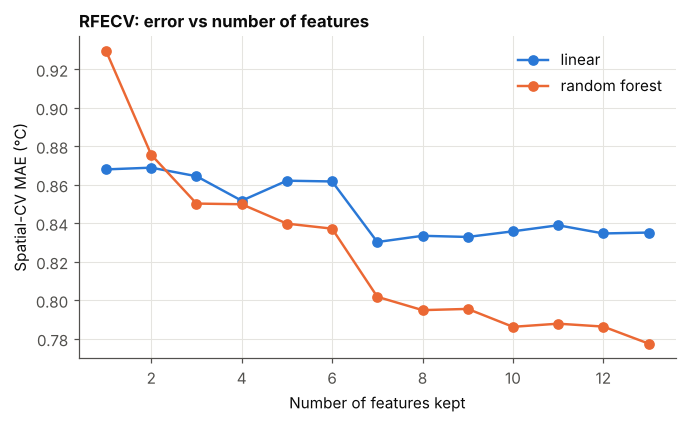

In [24]:
rfe_lin = RFE(LinearRegression(), n_features_to_select=1).fit(Xs, ytr)
filt["RFE rank (linear)"] = rfe_lin.ranking_

rfecv_lin = RFECV(LinearRegression(), step=1, cv=splits, scoring="neg_mean_absolute_error", min_features_to_select=1).fit(Xs, ytr)
rf_factory = lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.5, random_state=RANDOM_STATE, n_jobs=-1)
rfecv_rf = RFECV(rf_factory(), step=1, cv=splits, scoring="neg_mean_absolute_error", min_features_to_select=1).fit(Xs, ytr)

filt["RFECV linear"] = rfecv_lin.support_
filt["RFECV random forest"] = rfecv_rf.support_
print(f"RFECV linear keeps {rfecv_lin.n_features_} features; random forest keeps {rfecv_rf.n_features_}.")

fig, ax = plt.subplots(figsize=(7, 3.8))
for est, lab, col in [(rfecv_lin, "linear", BLUE), (rfecv_rf, "random forest", ORANGE)]:
    mae = -np.asarray(est.cv_results_["mean_test_score"])
    ax.plot(np.arange(1, len(mae) + 1), mae, marker="o", color=col, lw=1.6, label=lab)
ax.set_xlabel("Number of features kept"); ax.set_ylabel("Spatial-CV MAE (°C)")
ax.set_title("RFECV: error vs number of features"); ax.legend(frameon=False)
plt.show()

**How to read the plot:** Where the curve flattens, more variables give almost no gain, and that is where "fewer is enough" begins. RFECV picks the minimum; a sparser choice right at the flat part is often just as good and easier to explain.

### 5.3 Embedded: Lasso and random forest

**Lasso** penalises large coefficients and sets the useless ones to exactly 0 (linear, on standardised variables so the coefficients are comparable). **Random forest** measures how much each variable is used in the trees. Impurity importance is fast but favours variables with many distinct values and is confused by duplicates. We therefore add **permutation importance in the spatial folds**: we shuffle a variable's values in the validation part and see how much the error (MAE) grows. For duplicate clusters we shuffle the *whole cluster* at once (EDA impl. 3).

LassoCV: alpha = 0.0163; 10 of 13 coefficients ≠ 0


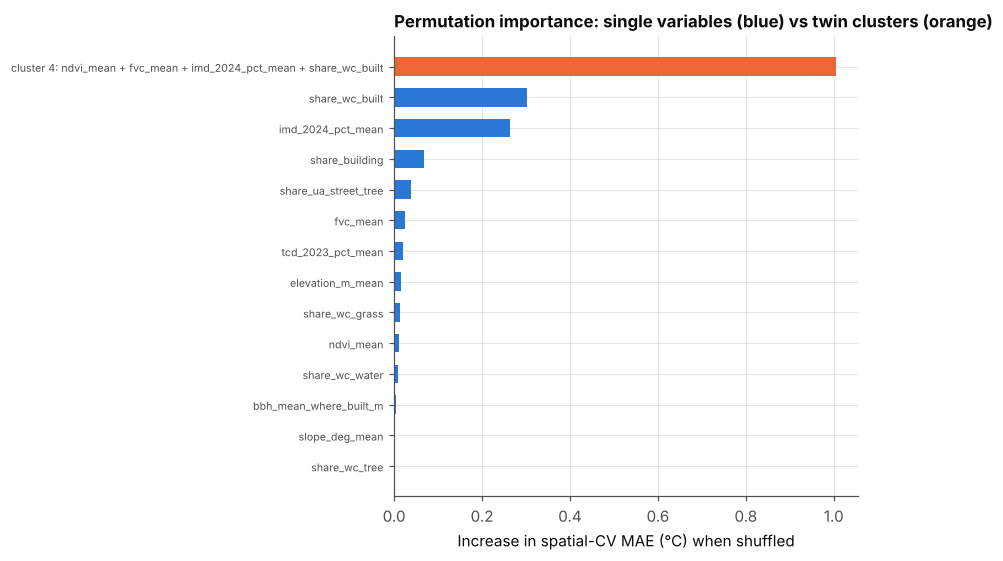

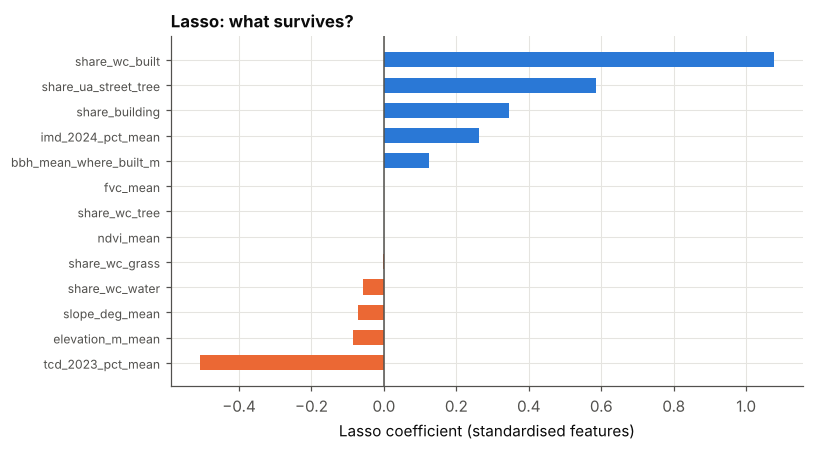

In [25]:
lasso = LassoCV(cv=splits, random_state=RANDOM_STATE, max_iter=50000).fit(Xs, ytr)
filt["Lasso coefficient"] = lasso.coef_
filt["Lasso ≠ 0"] = np.abs(lasso.coef_) > 1e-8
print(f"LassoCV: alpha = {lasso.alpha_:.4f}; {int(filt['Lasso ≠ 0'].sum())} of {len(feats)} coefficients ≠ 0")

rf_full = rf_factory().fit(Xtr, ytr)
filt["RF impurity importance"] = rf_full.feature_importances_

def grouped_permutation_importance(X, y, split_list, unit_cols, n_repeats=5, seed=RANDOM_STATE):
    """Spatial-CV permutation importance. unit_cols: {name: [columns]}; the columns in a unit are shuffled together (same row order)."""
    rng = np.random.default_rng(seed)
    out = {u: [] for u in unit_cols}
    for tr_i, va_i in split_list:
        m = rf_factory().fit(X.iloc[tr_i], y.iloc[tr_i])
        Xva, yva = X.iloc[va_i].reset_index(drop=True), y.iloc[va_i].reset_index(drop=True)
        base = mean_absolute_error(yva, m.predict(Xva))
        for u, cols in unit_cols.items():
            d_ = []
            for _ in range(n_repeats):
                Xp = Xva.copy()
                Xp[cols] = Xva[cols].values[rng.permutation(len(Xva))]
                d_.append(mean_absolute_error(yva, m.predict(Xp)) - base)
            out[u].append(np.mean(d_))
    return pd.DataFrame(out)

single_units = {c: [c] for c in feats}
cluster_units = {f"cluster {k_}: " + " + ".join(g.index): list(g.index) for k_, g in filt.groupby("cluster") if len(g) > 1}
perm_single = grouped_permutation_importance(Xtr, ytr, splits, single_units)
perm_cluster = grouped_permutation_importance(Xtr, ytr, splits, cluster_units) if cluster_units else pd.DataFrame()
filt["Permutation ΔMAE (°C)"] = perm_single.mean()

res_perm = pd.concat([perm_single.mean().rename("ΔMAE").to_frame().assign(unit="single variable"),
                      perm_cluster.mean().rename("ΔMAE").to_frame().assign(unit="whole duplicate cluster")]).sort_values("ΔMAE")
fig, ax = plt.subplots(figsize=(8, 5.2))
colors = [ORANGE if e == "whole duplicate cluster" else BLUE for e in res_perm["unit"]]
ax.barh(range(len(res_perm)), res_perm["ΔMAE"], color=colors, height=0.6)
ax.set_yticks(range(len(res_perm))); ax.set_yticklabels(res_perm.index, fontsize=7)
ax.set_xlabel("Increase in spatial-CV MAE (°C) when shuffled")
ax.set_title("Permutation importance: single variables (blue) vs twin clusters (orange)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.2))
lc = filt["Lasso coefficient"].sort_values()
ax.barh(range(len(lc)), lc.values, color=[BLUE if v >= 0 else ORANGE for v in lc.values], height=0.6)
ax.set_yticks(range(len(lc))); ax.set_yticklabels(lc.index, fontsize=8); ax.axvline(0, color=MUTED, lw=1)
ax.set_xlabel("Lasso coefficient (standardised features)"); ax.set_title("Lasso: what survives?")
plt.tight_layout(); plt.show()

**How to read them:** A ΔMAE close to 0 means the model does just as well without that variable, *but* if a duplicate covers for it, an important variable can look negligible. We therefore compare the blue bars (single variables) with the orange ones (whole clusters): if the cluster ranks high but each member ranks low, it is the *group* that matters, not a single member. Lasso coefficients are linear and can have opposite signs for duplicates (the EDA's OLS likewise gave unexpected signs for duplicate variables).

### 5.4 Overview: a vote between five methods

Each feature gets a vote from: (1) the filter, (2) RFECV linear, (3) RFECV random forest, (4) Lasso ≠ 0, (5) permutation ΔMAE ≥ `MIN_PERM_DELTA`. **This is a vote, not an answer key.** We use it to see what recurs and what only one method picks.

,filter,RFECV linear,RFECV RF,Lasso,Permutation,votes,cluster,|Spearman| with LST
share_wc_built,True,True,True,True,True,5,4,0.86
share_building,True,True,True,True,True,5,5,0.75
tcd_2023_pct_mean,True,True,True,True,True,5,1,0.64
share_wc_grass,True,True,True,True,True,5,7,0.60
share_ua_street_tree,True,True,True,True,True,5,3,0.26
elevation_m_mean,False,True,True,True,True,4,9,0.09
imd_2024_pct_mean,False,False,True,True,True,3,4,0.86
bbh_mean_where_built_m,True,False,True,True,False,3,6,0.66
share_wc_tree,True,True,True,False,False,3,2,0.53
share_wc_water,True,False,True,True,False,3,10,0.25



Selected by ≥ 3 of 5 methods: ['share_wc_built', 'share_building', 'tcd_2023_pct_mean', 'share_wc_grass', 'share_ua_street_tree', 'elevation_m_mean', 'imd_2024_pct_mean', 'bbh_mean_where_built_m', 'share_wc_tree', 'share_wc_water']
After duplicate pruning (one member per cluster): ['share_wc_built', 'share_building', 'tcd_2023_pct_mean', 'share_wc_grass', 'share_ua_street_tree', 'elevation_m_mean', 'bbh_mean_where_built_m', 'share_wc_tree', 'share_wc_water']
Stricter pruning at |Spearman| > 0.80 (Field et al.): ['share_wc_built', 'share_building', 'tcd_2023_pct_mean', 'share_wc_grass', 'share_ua_street_tree', 'elevation_m_mean', 'bbh_mean_where_built_m', 'share_wc_tree', 'share_wc_water']
Variance inflation factor (VIF): how much a coefficient's variance is inflated by the other predictors (1 = none).


,"VIF, all features","VIF, selected features"
share_wc_built,57.0,35.4
ndvi_mean,51.2,NaN
imd_2024_pct_mean,47.1,NaN
fvc_mean,40.5,NaN
share_wc_tree,22.8,20.8
share_wc_grass,16.5,16.2
share_building,6.0,4.4
share_wc_water,4.7,2.9
tcd_2023_pct_mean,4.0,3.0
share_ua_street_tree,2.8,2.7


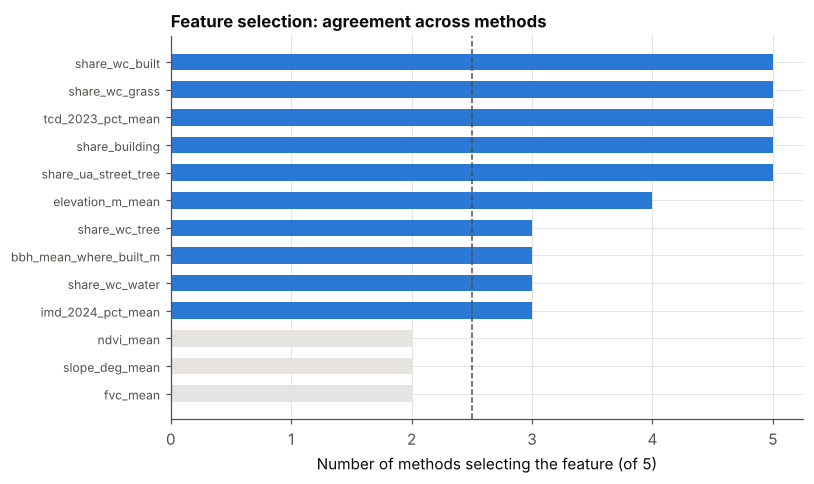

In [26]:
votes = pd.DataFrame({
    "filter": filt["passes filter"],
    "RFECV linear": filt["RFECV linear"],
    "RFECV RF": filt["RFECV random forest"],
    "Lasso": filt["Lasso ≠ 0"],
    "Permutation": filt["Permutation ΔMAE (°C)"] >= MIN_PERM_DELTA,
})
votes["votes"] = votes.sum(axis=1)
votes["cluster"] = filt["cluster"]
votes["|Spearman| with LST"] = filt["Spearman with LST"].abs().round(2)
votes = votes.sort_values(["votes", "|Spearman| with LST"], ascending=False)
display(votes)

shortlist_raw = list(votes.index[votes["votes"] >= MIN_VOTES])
# duplicate pruning: keep only one member per cluster (strongest vs LST)
shortlist = []
for k_, g in filt.loc[shortlist_raw].groupby("cluster"):
    shortlist.append(g["Spearman with LST"].abs().idxmax())
shortlist = [c for c in votes.index if c in shortlist]
# Stricter duplicate rule from Field et al. (2012, §17.4.2): no two kept variables with |Spearman| > 0.80
strict_cl = pd.Series(fcluster(lnk, t=1 - 0.80, criterion="distance"), index=feats)
shortlist_strict = []
for k_, g in filt.loc[shortlist_raw].groupby(strict_cl.loc[shortlist_raw]):
    shortlist_strict.append(g["Spearman with LST"].abs().idxmax())
shortlist_strict = [c for c in votes.index if c in shortlist_strict]
print(f"\nSelected by ≥ {MIN_VOTES} of 5 methods: {shortlist_raw}")
print(f"After duplicate pruning (one member per cluster): {shortlist}")
print(f"Stricter pruning at |Spearman| > 0.80 (Field et al.): {shortlist_strict}")

# Variance inflation factors (Park et al. 2022 report VIF as multicollinearity evidence; Field et al. 2012, §17.4.2 on multicollinearity)
def vif_table(X_):
    out = {}
    for c in X_.columns:
        others = X_.drop(columns=c)
        r2_ = LinearRegression().fit(others, X_[c]).score(others, X_[c])
        out[c] = 1 / (1 - r2_) if r2_ < 1 else np.inf
    return pd.Series(out)
vif_all = vif_table(Xs)
vif_sel = vif_table(Xs[shortlist]) if len(shortlist) > 1 else pd.Series(dtype=float)
print("Variance inflation factor (VIF): how much a coefficient's variance is inflated by the other predictors (1 = none).")
display(pd.concat([vif_all.rename("VIF, all features"), vif_sel.rename("VIF, selected features")], axis=1).round(1).sort_values("VIF, all features", ascending=False))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
vv = votes["votes"].sort_values()
ax.barh(range(len(vv)), vv.values, color=[BLUE if v >= MIN_VOTES else GRID for v in vv.values], height=0.6)
ax.set_yticks(range(len(vv))); ax.set_yticklabels(vv.index, fontsize=8); ax.set_xticks(range(0, 6))
ax.axvline(MIN_VOTES - 0.5, color=MUTED, lw=1, ls="--")
ax.set_xlabel("Number of methods selecting the feature (of 5)"); ax.set_title("Feature selection: agreement across methods")
plt.tight_layout(); plt.show()

**What the VIF table adds (Park et al. 2022 report VIF as multicollinearity evidence).** Among all 13 features the VIFs of built-up share (57), NDVI (51), imperviousness (47) and fvc (41) are very large, and tree (23) and grass (17) share are also high. Our duplicate pruning removes NDVI, fvc and imperviousness, but the selected nine still contain **all four WorldCover shares**; water is harmless (VIF 2.9, it is zero in most cells), but built-up (35), tree (21) and grass (16) are not. The reason is that the four shares add up to about 1 in most cells (median 1.000), so any one of them is nearly a linear function of the others. Consequences: (i) a **random forest** is not troubled by this, (ii) a **linear regression** will predict fine but its individual coefficients are unstable and must not be read as "the effect of tree cover", (iii) for a regression or neural network that we want to *interpret*, we should either drop one share (reference category) or use the factor scores from Part 4. The pair `share_wc_built` / `share_building` has Pearson r = .84 (above Field et al.'s .8), but their Spearman correlation is below .80, so a stricter duplicate rule at .80 selects the same nine variables; we keep both because each is individually informative in the permutation test, and flag the VIF.

### 5.5 Do the selected features actually predict as well? (spatial CV on train)

**Intuition.** A selection is only good if it performs almost as well as "all variables" on cells it has not seen (geographically new folds). We compare:

* **all** features, the **vote-based selection**, and **imperviousness only** (the EDA's suggested baseline, impl. 5),
* the **Lasso selection** and the **RFECV selections**,
* **PCA with K components** (dimensionality reduction instead of selection). PCA and the scaler are fitted *inside each fold* via a `Pipeline`, so no information leaks. A varimax rotation does not change OLS predictions (same subspace), so we leave it out here.

Models: linear regression and random forest. Error measures: MAE (°C) and R².

MAE                   R²              
model                     linear random forest linear random forest
feature set            n                                           
Lasso selection        10  0.787         0.773  0.658         0.675
PCA, 3 components      3   0.879         0.876  0.543         0.589
RFECV RF selection     13  0.835         0.777  0.618         0.664
RFECV linear selection 7   0.799         0.772  0.656         0.674
all features           13  0.835         0.777  0.618         0.664
imperviousness only    1   0.894         0.929  0.552         0.508
vote-based selection   9   0.820         0.770  0.633         0.676

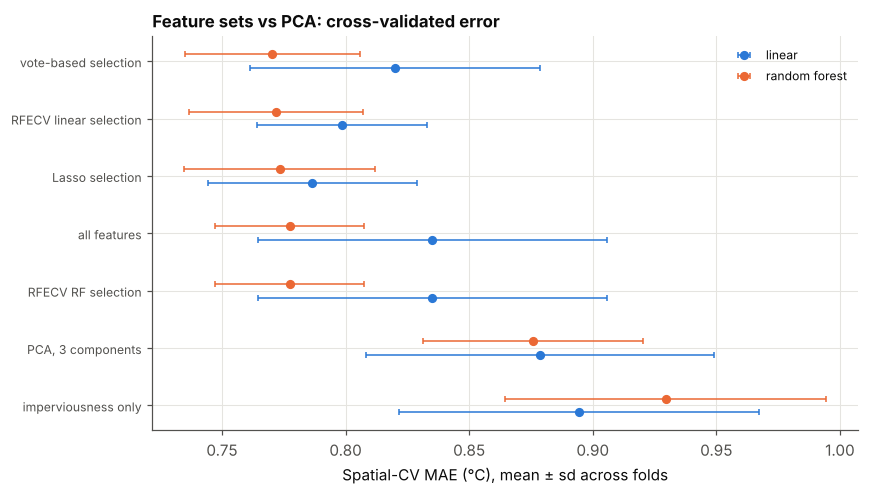

In [27]:
sets = {"all features": feats}
if shortlist: sets["vote-based selection"] = shortlist
if shortlist_strict and set(shortlist_strict) != set(shortlist): sets["vote-based, strict 0.80 pruning"] = shortlist_strict
if "imd_2024_pct_mean" in feats: sets["imperviousness only"] = ["imd_2024_pct_mean"]
lasso_set = [c for c in feats if filt.loc[c, "Lasso ≠ 0"]]
if lasso_set: sets["Lasso selection"] = lasso_set
sets["RFECV linear selection"] = [c for c in feats if filt.loc[c, "RFECV linear"]]
sets["RFECV RF selection"] = [c for c in feats if filt.loc[c, "RFECV random forest"]]

def cv_eval(model, cols):
    r = cross_validate(model, Xtr[cols], ytr, cv=splits, scoring={"mae": "neg_mean_absolute_error", "r2": "r2"})
    return -r["test_mae"].mean(), r["test_mae"].std(), r["test_r2"].mean()

rows = []
for name, cols in sets.items():
    for mname, mk in [("linear", lambda: Pipeline([("s", StandardScaler()), ("m", LinearRegression())])), ("random forest", rf_factory)]:
        mae, sd, r2 = cv_eval(mk(), cols)
        rows.append({"feature set": name, "n": len(cols), "model": mname, "MAE": mae, "± sd (folds)": sd, "R²": r2})
for mname, mk in [("linear", lambda: LinearRegression()), ("random forest", rf_factory)]:
    pipe = Pipeline([("s", StandardScaler()), ("pca", PCA(n_components=K)), ("m", mk())])
    mae, sd, r2 = cv_eval(pipe, feats)
    rows.append({"feature set": f"PCA, {K} components", "n": K, "model": mname, "MAE": mae, "± sd (folds)": sd, "R²": r2})
cv_res = pd.DataFrame(rows)
display(cv_res.pivot_table(index=["feature set", "n"], columns="model", values=["MAE", "R²"]).round(3))

fig, ax = plt.subplots(figsize=(8, 4.6))
order = cv_res.groupby("feature set")["MAE"].min().sort_values(ascending=False).index.tolist()
ypos = {u: i for i, u in enumerate(order)}
for mname, col, off in [("linear", BLUE, -0.12), ("random forest", ORANGE, 0.12)]:
    sub = cv_res[cv_res["model"] == mname]
    ax.errorbar(sub["MAE"], [ypos[u] + off for u in sub["feature set"]], xerr=sub["± sd (folds)"], fmt="o", color=col, ms=5, lw=1, capsize=2, label=mname)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
ax.set_xlabel("Spatial-CV MAE (°C), mean ± sd across folds"); ax.set_title("Feature sets vs PCA: cross-validated error"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### 5.5b Dimension reduction done properly: tune the number of PCA components (Géron, ch. 8)

Géron treats the number of components as a **hyperparameter** that we tune inside a pipeline (here: standardise → PCA(k) → model, refitted in every spatial fold) instead of fixing it by a rule of thumb. Two things make this fairer to PCA than the single K = Kaiser run above: (i) a nonlinear model such as a random forest may need a different k than a linear one, and (ii) Field et al. (2012, §17.3.3.2) point out that factor scores can be used in a regression to avoid multicollinearity, but then it pays to *keep more* components rather than fewer, because dropped components may still carry information about the outcome. We also report the **reconstruction error**, i.e. how much of the standardised data cannot be recovered from k components (the information lost by compression).

,MAE (linear),MAE (random forest),R² (linear),R² (random forest),reconstruction error
k,,,,,
1,0.949,1.001,0.441,0.387,0.489
2,0.909,0.900,0.507,0.532,0.303
3,0.879,0.876,0.543,0.589,0.216
4,0.879,0.874,0.542,0.581,0.142
5,0.864,0.861,0.563,0.595,0.093
6,0.858,0.830,0.575,0.623,0.064
7,0.819,0.820,0.621,0.630,0.042
8,0.799,0.781,0.638,0.662,0.023
9,0.801,0.782,0.638,0.667,0.010


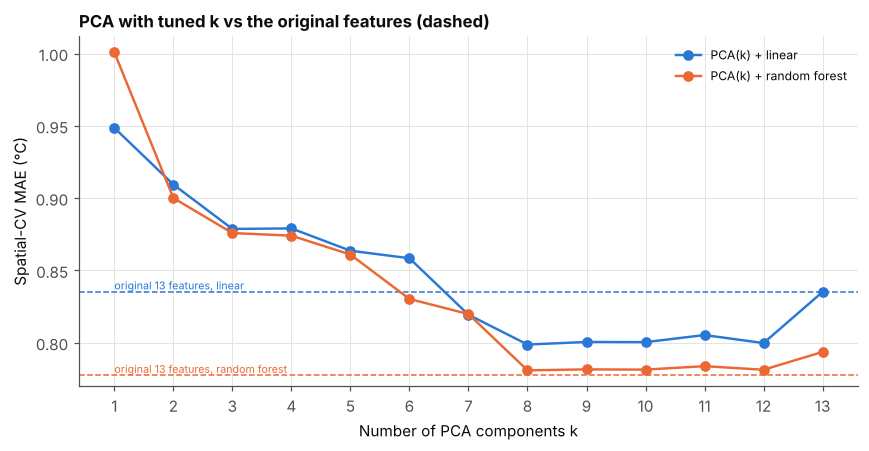

linear        : best k = 8, spatial-CV MAE = 0.799 (± 0.053) vs original 13 features = 0.835
random forest : best k = 8, spatial-CV MAE = 0.781 (± 0.040) vs original 13 features = 0.777
Note: choosing k on the same folds that we report is slightly optimistic for PCA; it still has to beat the original features to be preferred.


In [28]:
Zfull = StandardScaler().fit_transform(Xtr)
pca_rows = []
for k in range(1, len(feats) + 1):
    pk = PCA(n_components=k).fit(Zfull)
    rec_err = float(((Zfull - pk.inverse_transform(pk.transform(Zfull))) ** 2).mean())
    for mname, mk in [("linear", lambda: LinearRegression()), ("random forest", rf_factory)]:
        pipe = Pipeline([("s", StandardScaler()), ("pca", PCA(n_components=k)), ("m", mk())])
        mae, sd, r2 = cv_eval(pipe, feats)
        pca_rows.append({"k": k, "model": mname, "MAE": mae, "± sd (folds)": sd, "R²": r2, "reconstruction error": rec_err})
pca_cv = pd.DataFrame(pca_rows)
pv = pca_cv.pivot_table(index="k", columns="model", values=["MAE", "R²"])
pv.columns = [f"{a} ({b})" for a, b in pv.columns]
display(pv.assign(**{"reconstruction error": pca_cv.drop_duplicates("k").set_index("k")["reconstruction error"]}).round(3))

best_k = pca_cv.loc[pca_cv.groupby("model")["MAE"].idxmin()].set_index("model")
ref = cv_res.pivot_table(index="feature set", columns="model", values="MAE")
fig, ax = plt.subplots(figsize=(8, 4.2))
for mname, col in [("linear", BLUE), ("random forest", ORANGE)]:
    sub = pca_cv[pca_cv["model"] == mname]
    ax.plot(sub["k"], sub["MAE"], marker="o", color=col, lw=1.6, label=f"PCA(k) + {mname}")
    ax.axhline(ref.loc["all features", mname], color=col, lw=1, ls="--")
ax.text(1, ref.loc["all features", "linear"], "original 13 features, linear", color=BLUE, fontsize=7, va="bottom", ha="left")
ax.text(1, ref.loc["all features", "random forest"], "original 13 features, random forest", color=ORANGE, fontsize=7, va="bottom", ha="left")
ax.set_xlabel("Number of PCA components k"); ax.set_ylabel("Spatial-CV MAE (°C)"); ax.set_xticks(range(1, len(feats) + 1))
ax.set_title("PCA with tuned k vs the original features (dashed)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
for mname in best_k.index:
    print(f"{mname:14s}: best k = {int(best_k.loc[mname, 'k'])}, spatial-CV MAE = {best_k.loc[mname, 'MAE']:.3f} (± {best_k.loc[mname, '± sd (folds)']:.3f}) "
          f"vs original 13 features = {ref.loc['all features', mname]:.3f}")
print("Note: choosing k on the same folds that we report is slightly optimistic for PCA; it still has to beat the original features to be preferred.")

**What tuning k tells us (Géron, ch. 8; Karam 2026b).**

* With the Kaiser choice of **3 components** PCA is clearly worse than the original features (MAE 0.88 vs 0.78 to 0.84), because it throws away information the models can use: reconstruction error at k = 3 is 22% of the standardised variance.
* Tuning k changes the picture. Both models do best around **k = 8** (spatial-CV MAE 0.80 linear, 0.78 random forest), where only about 2% of the information is lost. The curve is flat from k = 8 onwards.
* For the **linear model** PCA(8) (0.80) is better than the 13 original features (0.84), because the original features are strongly multicollinear (VIF above) and the components are uncorrelated by construction. This is exactly the use of factor scores that Field et al. (2012, §17.3.3.2) describe. But a *selection* does about as well without any new variables: Lasso (0.79), RFECV linear (0.80), and the nine vote-based features (0.82); the fold spread is 0.03 to 0.07, so these differences are **not** conclusive.
* For the **random forest** PCA gives no gain (0.78 vs 0.78 for all 13 and 0.77 for the nine selected): trees do not need decorrelated inputs.

**So, in line with "original data first" (Karam 2026b; Géron, ch. 8):** dimension reduction is only worth its cost in interpretability for a *linear* model with many collinear inputs, and even then feature selection (or dropping one WorldCover share) gets nearly the same result. We use PCA/factor scores mainly to **understand the structure** and as an option for the linear model, not as the default input.

**We read the result with these caveats:**

* Differences smaller than the spread between folds (± sd) are not something we can base a conclusion on.
* Spatial CV is still *optimistic* compared with predicting a completely new area, since neighbouring cells in other folds still resemble each other.
* "Fewer variables ≈ same error" is good news (a simpler model), but it does **not** mean that the dropped variables are irrelevant in reality. They may simply be redundant *given* the others.
* LST is a modelled product (CLIM4cities, cf. EDA); part of the NDVI/imperviousness signal may reflect the algorithm. This is unresolved.

### 5.6 One look at the test set (the easternmost 20%)

Only now do we use the test set, and only to **report**. We do not choose a feature set based on the test result (that would turn it into a validation set). For comparison we can look at the group's own random forest on the same eastern test set; cutoff and features may differ, so we should not expect identical numbers.

In [29]:
if EVALUATE_ON_TEST:
    Xte = test[feats].reset_index(drop=True); yte = y_te.reset_index(drop=True)
    rows = []
    for name in [n for n in ["all features", "vote-based selection", "imperviousness only"] if n in sets]:
        cols = sets[name]
        for mname, mk in [("linear", lambda: Pipeline([("s", StandardScaler()), ("m", LinearRegression())])), ("random forest", rf_factory)]:
            m = mk().fit(Xtr[cols], ytr); pred = m.predict(Xte[cols])
            rows.append({"feature set": name, "model": mname, "MAE": mean_absolute_error(yte, pred),
                         "RMSE": mean_squared_error(yte, pred) ** 0.5, "R²": r2_score(yte, pred)})
    for mname, mk in [("linear", lambda: LinearRegression()), ("random forest", rf_factory)]:
        kb = int(best_k.loc[mname, "k"])
        pipe = Pipeline([("s", StandardScaler()), ("pca", PCA(n_components=kb)), ("m", mk())]).fit(Xtr, ytr)
        pred = pipe.predict(Xte)
        rows.append({"feature set": f"PCA, k = {kb} (tuned)", "model": mname, "MAE": mean_absolute_error(yte, pred),
                     "RMSE": mean_squared_error(yte, pred) ** 0.5, "R²": r2_score(yte, pred)})
    display(pd.DataFrame(rows).round(3).set_index(["feature set", "model"]))
else:
    print("EVALUATE_ON_TEST = False – the test set has not been touched.")

MAE   RMSE     R²
feature set          model                             
all features         linear         0.740  0.949  0.746
                     random forest  0.660  0.871  0.786
vote-based selection linear         0.753  0.963  0.738
                     random forest  0.675  0.895  0.774
imperviousness only  linear         0.873  1.101  0.658
                     random forest  0.885  1.137  0.635
PCA, k = 8 (tuned)   linear         0.725  0.940  0.750
                     random forest  0.730  0.952  0.744

**Reading the test table.** On the eastern test strip the picture agrees with the cross-validation, with a bit more noise (211 cells): the random forest on all features is best (MAE 0.66, R² 0.79), the nine selected features lose only about 0.015 °C (0.675), imperviousness alone is clearly worse (0.87 to 0.89), and PCA with the CV-tuned k = 8 helps the linear model (0.725 vs 0.740 for all 13) but not the random forest (0.730 vs 0.660). We report these numbers; we did **not** choose anything based on them.

## Part 6. Sensitivity analysis: does the treatment of missing data change our conclusions?

**Intuition.** When we do not know what an empty field means, the wisest move is to try several reasonable assumptions and see whether the points change. If they do *not*, the provider's answer need not change our conclusions. If they do, we know exactly where it matters.

For each strategy in `STRATEGIES` we run a compact version of the pipeline (new rows, same spatial split): number of rows, what is dropped, KMO, number of components, cumulative variance, the strongest variables by Spearman, and the Lasso selection.

In [30]:
def quick_summary(strategy):
    tr, te, fe = apply_missing_strategy(train_raw, test_raw, FEATURES, strategy)
    gone = train_raw[~train_raw[ID].isin(tr[ID])]
    X = tr[fe]
    cols, drop_log = drop_low_msa(X, MSA_MIN)
    Z = StandardScaler().fit_transform(X[cols])
    kmo = calculate_kmo(Z)[1]
    pc = PCA().fit(Z)
    rho = X.apply(lambda c: c.corr(tr[TARGET], method="spearman")).abs().sort_values(ascending=False)
    sp_, _ = make_splits(tr)
    las = LassoCV(cv=sp_, random_state=RANDOM_STATE, max_iter=50000).fit(StandardScaler().fit_transform(X), tr[TARGET])
    return {
        "strategy": strategy, "train rows": len(tr), "dropped from train": len(gone),
        "LST in dropped (°C)": round(gone[TARGET].mean(), 2) if len(gone) else np.nan,
        "LST in kept (°C)": round(tr[TARGET].mean(), 2),
        "features": len(fe), "KMO": round(kmo, 3), "dropped (MSA)": ", ".join(d["dropped"] for d in drop_log) or "-",
        "Kaiser K": int((pc.explained_variance_ > 1).sum()), "variance in 3 PCs": round(pc.explained_variance_ratio_[:3].sum(), 3),
        "top-3 |Spearman|": ", ".join(rho.index[:3]),
        "Lasso ≠ 0": ", ".join(c for c, b in zip(fe, las.coef_) if abs(b) > 1e-8),
    }

sens = pd.DataFrame([quick_summary(s) for s in STRATEGIES]).set_index("strategy")
display(sens.drop(columns=["Lasso ≠ 0"]))
print("\nLasso selection per strategy:")
for s, v in sens["Lasso ≠ 0"].items():
    print(f"  {s:16s} {v}")

,train rows,dropped from train,LST in dropped (°C),LST in kept (°C),features,KMO,dropped (MSA),Kaiser K,variance in 3 PCs,top-3 |Spearman|
strategy,,,,,,,,,,
structural_zero,948,2,31.06,33.57,13,0.770,share_wc_water,3,0.838,"share_wc_built, imd_2024_pct_mean, fvc_mean"
complete_case,823,127,30.53,34.03,13,0.860,"share_wc_water, share_wc_grass, elevation_m_mean",2,0.891,"share_wc_built, imd_2024_pct_mean, fvc_mean"
drop_bbh,948,2,31.06,33.57,12,0.868,"share_wc_water, share_wc_grass, elevation_m_me...",2,0.932,"share_wc_built, imd_2024_pct_mean, fvc_mean"
median_all,950,0,NaN,33.56,13,0.863,"share_wc_water, share_wc_grass, elevation_m_mean",2,0.876,"share_wc_built, imd_2024_pct_mean, fvc_mean"
iterative,950,0,NaN,33.56,13,0.768,share_wc_water,3,0.835,"share_wc_built, imd_2024_pct_mean, fvc_mean"



Lasso selection per strategy:
  structural_zero  imd_2024_pct_mean, tcd_2023_pct_mean, elevation_m_mean, slope_deg_mean, share_wc_grass, share_wc_built, share_wc_water, share_ua_street_tree, share_building, bbh_mean_where_built_m
  complete_case    fvc_mean, imd_2024_pct_mean, tcd_2023_pct_mean, elevation_m_mean, slope_deg_mean, share_wc_built, share_wc_water, share_ua_street_tree, share_building
  drop_bbh         fvc_mean, imd_2024_pct_mean, tcd_2023_pct_mean, elevation_m_mean, slope_deg_mean, share_wc_grass, share_wc_built, share_wc_water, share_ua_street_tree, share_building
  median_all       fvc_mean, imd_2024_pct_mean, tcd_2023_pct_mean, elevation_m_mean, slope_deg_mean, share_wc_tree, share_wc_grass, share_wc_built, share_wc_water, share_ua_street_tree, share_building, bbh_mean_where_built_m
  iterative        imd_2024_pct_mean, tcd_2023_pct_mean, elevation_m_mean, slope_deg_mean, share_wc_grass, share_wc_built, share_wc_water, share_ua_street_tree, share_building, bbh_mean_wh

**How to read Part 6.**

* **Dropped from train / LST in dropped:** if *complete-case* removes many cells and their mean LST differs clearly from the kept ones, the gaps are not random and the strategy is biased.
* **Same KMO, same K, same top variables and nearly the same Lasso selection across strategies** = the conclusions are robust to how we treat the gaps.
* `median_all` is included *to show the danger*: filling "no buildings" with the median building height invents buildings where there are none.

**What the provider's answer will change.** If NaN means 0 (e.g. no trees), the variables concerned should be filled with 0, and cell means such as tree cover must be recomputed, since they are otherwise skewed high (EDA: *NaN is undefined*). If NaN means "not measured", imputation or deletion is the right choice. For the few cells affected outside building height, Part 2 shows how little it matters.

## Part 7. Save results for the group's models

In [31]:
meta = {
    "missing_strategy": MISSING_STRATEGY, "n_train": int(len(train)), "n_test": int(len(test)),
    "split_longitude_cut": float(cut), "features_used": feats, "fa_features": fa_cols, "fa_dropped_msa": [d["dropped"] for d in msa_log],
    "n_components": K, "shortlist_votes": shortlist, "shortlist_strict_080": shortlist_strict, "shortlist_before_twin_pruning": shortlist_raw,
    "lasso_set": lasso_set, "excluded_columns": EXCLUDED, "loading_cutoff": LOADING_CUTOFF,
    "k_rules": {k_: int(v_) for k_, v_ in rules.items()}, "pca_best_k_cv": {m_: int(best_k.loc[m_, "k"]) for m_ in best_k.index},
}
with open(f"{OUTPUT_DIR}/selection_summary.json", "w", encoding="utf-8") as fh:
    json.dump(meta, fh, ensure_ascii=False, indent=2)
votes.to_csv(f"{OUTPUT_DIR}/feature_votes.csv")
L_rot.to_csv(f"{OUTPUT_DIR}/varimax_loadings.csv")
cv_res.to_csv(f"{OUTPUT_DIR}/cv_comparison.csv", index=False)
sens.to_csv(f"{OUTPUT_DIR}/missing_data_sensitivity.csv")
pca_cv.to_csv(f"{OUTPUT_DIR}/pca_k_tuning_cv.csv", index=False)
L_obl.to_csv(f"{OUTPUT_DIR}/oblimin_loadings.csv"); phi.to_csv(f"{OUTPUT_DIR}/oblimin_factor_correlations.csv")
h2.to_csv(f"{OUTPUT_DIR}/communalities.csv")
pd.concat([vif_all.rename("vif_all"), vif_sel.rename("vif_selected")], axis=1).to_csv(f"{OUTPUT_DIR}/vif.csv")
pd.concat([train[[ID, LON, LAT, TARGET]].reset_index(drop=True), F_tr.reset_index(drop=True)], axis=1).assign(split="train").to_csv(f"{OUTPUT_DIR}/factor_scores_train.csv", index=False)
pd.concat([test[[ID, LON, LAT, TARGET]].reset_index(drop=True), F_te.reset_index(drop=True)], axis=1).assign(split="test").to_csv(f"{OUTPUT_DIR}/factor_scores_test.csv", index=False)
print("Saved in", OUTPUT_DIR + "/:", sorted(os.listdir(OUTPUT_DIR)))

Saved in outputs_fa_fs/: ['communalities.csv', 'cv_comparison.csv', 'factor_scores_test.csv', 'factor_scores_train.csv', 'feature_votes.csv', 'missing_data_sensitivity.csv', 'oblimin_factor_correlations.csv', 'oblimin_loadings.csv', 'pca_k_tuning_cv.csv', 'selection_summary.json', 'varimax_loadings.csv', 'vif.csv']


## Part 8. Decisions, course alignment and what the notebook *cannot* say

**Decisions and the source they rest on**

| Decision | Source | Where |
|---|---|---|
| "FA" = PCA + varimax on physical variables; axes are summaries, not reflective constructs; alpha is descriptive | Karam (2026a); Field et al. (2012, §17.3.6); Park et al. (2022) as the contrasting case | 4 intro, 4.6 |
| Screen correlations: |r| > .8 pairs, r < .3 variables, determinant > 0.00001 | Field et al. (2012, §17.4.2) | 4.1 |
| KMO/MSA and Bartlett; drop variables with MSA < 0.5 (`share_wc_water`) | Karam (2026a); Field et al. (2012) | 4.2 |
| K = 3 (Kaiser/elbow/80%); parallel analysis says 2 and PC3 is borderline | Karam (2026a); Field et al. (2012, §17.3.8) | 4.3 |
| Communalities; Kaiser acceptable under condition B (n > 250, mean communality .84 ≥ .6) | Karam (2026a); Field et al. (2012, §17.3.5) | 4.5b |
| Loading cut-off 0.4 (0.3 and 0.5 shown) | Field et al. (2012, §17.3.9.2); Karam (2026a) | 4.5 |
| Varimax for exported scores; oblimin and principal-axis factoring as robustness (same grouping; largest factor correlation 0.32) | Field et al. (2012, §17.3.6, §17.3.9) | 4.5c, 4.5d |
| Feature selection (filter + wrapper + embedded) on the original variables; duplicate pruning; VIF reported | Karam (2026b); Park et al. (2022) for VIF reporting | 5.1 to 5.4 |
| Original features first; PCA with k tuned by spatial CV, reconstruction error reported | Karam (2026b); Géron (ch. 8); Field et al. (2012, §17.3.3.2) | 5.5, 5.5b |

**What this means for the ML step.** (1) Start from the **original features**: all 13, or the nine-variable selection as the lean alternative; they predict about equally well. (2) For a **random forest** nothing needs to be reduced. (3) For a **linear model or neural network** whose inputs we want to interpret, deal with the compositional WorldCover shares (drop one or use factor scores / PCA with about 8 components); do not interpret individual coefficients of the shares. (4) Do not use PCA with 3 components as the model input: it loses too much (MAE 0.88).

**Interpretation tasks** (to be done in our own words, with reference to the output above):
1. Name the rotated axes in 4.5 and justify the number of components (4.3).
2. Which variables recur across the methods in 5.4, and which are selected by only one? Why do we think so?
3. Is the difference between "all features" and the selection in 5.5 larger than the spread between folds?
4. Does the treatment of missing data change anything in Part 6? What should we ask the provider?

**Limitations** (cf. EDA: *What the EDA cannot tell us*):
* One day, one time (13 June 2023). LST is surface temperature, not air temperature or human heat experience.
* The target is a modelled product; the algorithm may have contributed to the NDVI/imperviousness signal.
* Neighbouring cells are not independent: spatial CV reduces the problem but does not remove it.
* PCA, varimax and Lasso are linear; the random forest part captures non-linearity, but the comparisons are correlation-based, not causal.
* The factor analysis covers only land cells with LST; coast and water are not included.
* Our default `structural_zero` rests on the assumption, supported by the data in 2.2, that empty building height means no buildings. We should confirm this with the data provider. Under `complete_case` the cells without buildings would be lost (they are cooler, cf. 2.2 and Part 6).